<hr>

**<h1><b> CS437/CS5317/EE414/EE513 Deep Learning | <span style="color: #9370DB;"> PA2 - Part 1</span></b></h1>**

<hr>

## <span style="color: #abaea0;">**Submission Guidelines**</span>

- <span style="color: #9370DB;">Please rename the file to `<RollNumber>_PA2_Part1`.</span>
- <span style="color: #9370DB;">Please also submit a **.py** file of every Notebook. You can do this by exporting your **ipynb** to a Python script.</span>
- <span style="color: #9370DB;">Please submit a zipped folder of both your Jupyter Notebooks and Python script files.</span>
- <span style="color: #9370DB;">Please submit a JSON file containing the outputs of all the parts.</span>

In [1]:
# ============ Import Libraries =============
import warnings
warnings.filterwarnings('ignore')
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
from torchsummary import summary
import random
import matplotlib.pyplot as plt
import torchvision.utils as vutils
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, adjusted_rand_score, normalized_mutual_info_score
import json

# =========== Student Information ===========
Name = "Sameer Rahil"
Roll_Number = 27100162

# =========== Device Configuration ==========
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # GPU is available or not
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu') # MPS is available or not - Only for Macbook M1 and above
print(f"Device: {device}")

# =========== Visualization Function ==========
def imshow(img, dataset_name):
    img = img
    npimg = img.numpy()
    plt.figure(figsize=(10, 10))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.title(f"Random Batch of Images from the {dataset_name} Dataset")
    plt.show()


Device: cpu


<hr>

## <h1><b> Part 1: Linear Autoencoders and Autoencoders Using CNN in PyTorch <span style="color: #9370DB;"> (75 Points Total)</span></b></h1>  

<hr>

### <h2><b> Introduction </b></h2>  
<p>Autoencoders are a type of <b>unsupervised neural network</b> designed to learn efficient data representations. They consist of two main components:</p>  
<ul>  
    <li><b>Encoder:</b> Compresses the input into a lower-dimensional latent space.</li>  
    <li><b>Decoder:</b> Reconstructs the original input from the encoded representation.</li>  
</ul>  

<p>This structure makes autoencoders useful for various tasks, including:</p>  
<ul>  
    <li>Dimensionality reduction</li>
    <li>Noise removal (denoising autoencoders)</li>  
    <li>Anomaly detection</li>  
    <li>Feature extraction for downstream tasks</li>  
</ul>

<hr>  

<h2><b> Linear and Convolutional Autoencoders </b></h2>  
<p>In this task, we explore two types of autoencoders:</p>  

<ul>
    <li><b>Linear Autoencoder:</b> Uses fully connected layers and learns a compressed representation of the input in a linear fashion, often simpler and less computationally intensive than convolutional variants.</li>
    <li><b>Convolutional Autoencoder (CAE):</b> Replaces fully connected layers with <b>convolutional layers</b>, making it more effective for image processing. CAEs leverage spatial hierarchies in images, capturing key features while preserving important structures.</li>    
</ul>

<hr>  

<h2><b> CIFAR-10 and MNIST Datasets </b></h2>  
<p>The <b>CIFAR-10 dataset</b> is a commonly used benchmark dataset for deep learning research. It consists of <b>60,000 color images</b> (32x32 pixels), divided into <b>10 classes</b> representing different objects:</p>  

<table border="1" cellpadding="10" cellspacing="0" style="border-collapse: collapse; text-align: center;">  
    <tr style="background-color:rgb(60, 60, 60);">  
        <th><b>Class</b></th>  
        <th>Airplane</th>  
        <th>Automobile</th>  
        <th>Bird</th>  
        <th>Cat</th>  
        <th>Deer</th>  
        <th>Dog</th>  
        <th>Frog</th>  
        <th>Horse</th>  
        <th>Ship</th>  
        <th>Truck</th>  
    </tr>  
    <tr>  
        <th style="background-color:rgb(60, 60, 60);"><b>Label</b></th>  
        <td>0</td>  
        <td>1</td>  
        <td>2</td>  
        <td>3</td>  
        <td>4</td>  
        <td>5</td>  
        <td>6</td>  
        <td>7</td>  
        <td>8</td>  
        <td>9</td>  
    </tr>  
</table>  

<p>The <b>MNIST dataset</b> contains <b>60,000 grayscale images</b> (28x28 pixels) of handwritten digits, divided into <b>10 classes</b> (digits 0-9), used primarily for digit classification and image reconstruction tasks.</p>  

<hr>

<h2><b> Objectives </b></h2>  

<ul>  
    <li>Implement an <b>Autoencoder</b> using two architectures: <b>Linear Autoencoder</b> and <b>Convolutional Autoencoder (CNN)</b>.</li>  
    <li>Design and implement <b>Encoder</b> and <b>Decoder</b> modules in PyTorch.</li>  
    <li>Train the models on <b>CIFAR-10</b> and <b>MNIST</b> datasets, evaluating their reconstruction quality.</li>  
    <li>Test the Autoencoders in <b>six scenarios</b>, each demonstrating a key application:</li>  
    <ul>
        <li>Linear Autoencoder - Reconstruction (CIFAR-10)</li>
        <li>Convolutional Autoencoder - Reconstruction (CIFAR-10)</li>
        <li>Linear Autoencoder - Denoising (MNIST)</li>
        <li>Convolutional Autoencoder - Denoising (MNIST)</li>
        <li>CNN Image Classification Analysis - CIFAR-10 Reconstruction</li>
        <li>CNN Image Classification Analysis - MNIST Denoising</li>
    </ul>
    <li>Extend the applications by implementing <b>Task 7: Generating Images using Latent Space</b> for advanced understanding and performance evaluation.</li>
</ul>  

<br>

<table border="1" cellpadding="10" cellspacing="0" width="100%">  
    <tr>  
        <th><b>Scenario</b></th>  
        <th><b>Description</b></th>  
        <th><b>Purpose</b></th>  
    </tr>  
    <tr>  
        <td><b>1. Linear Autoencoder - Reconstruction (CIFAR-10)</b></td>  
        <td>Train and test a linear autoencoder on the CIFAR-10 dataset for image reconstruction.</td>  
        <td>Demonstrates the ability of a linear autoencoder to learn compressed representations and reconstruct images from CIFAR-10.</td>  
    </tr>  
    <tr>  
        <td><b>2. Convolutional Autoencoder - Reconstruction (CIFAR-10)</b></td>  
        <td>Train and test a convolutional autoencoder on CIFAR-10 images for image reconstruction.</td>  
        <td>Shows how convolutional layers can capture spatial features and improve reconstruction performance on CIFAR-10.</td>  
    </tr>  
    <tr>  
        <td><b>3. Linear Autoencoder - Denoising (MNIST)</b></td>  
        <td>Train the model on noisy MNIST images and test its ability to reconstruct clean images.</td>  
        <td>Demonstrates how a linear autoencoder can filter noise and recover the original images from noisy inputs.</td>  
    </tr>  
    <tr>  
        <td><b>4. Convolutional Autoencoder - Denoising (MNIST)</b></td>  
        <td>Train the convolutional autoencoder on noisy MNIST digits and test its denoising capabilities.</td>  
        <td>Shows how convolutional autoencoders can better denoise images by leveraging spatial hierarchies in image data.</td>  
    </tr>
    <tr>  
        <td><b>5. CNN Image Classification Analysis - CIFAR-10 Reconstruction</b></td>  
        <td>Train a CNN on clean CIFAR-10 images and evaluate its performance on the original test data, LAERecon reconstructed test data, and CAERecon reconstructed test data.</td>  
        <td>Assesses how well the reconstructions preserve essential features for classification.</td>  
    </tr>  
    <tr>  
        <td><b>6. CNN Image Classification Analysis - MNIST Denoising</b></td>  
        <td>Train a CNN on clean MNIST images and evaluate its performance on the original test data, LAEDenoise reconstructed test data, and CAEDenoise reconstructed test data.</td>  
        <td>Assesses how well the denoising reconstructions preserve essential features for classification.</td>  
    </tr>  
    <tr>  
        <td><b>7. Generating Images using Latent Space</b></td>  
        <td>Sample random vectors from the latent space and pass them through the decoder to generate new images.</td>  
        <td>Evaluate the potential of autoencoders for generating realistic images from latent space representations.</td>  
    </tr>  
</table>  

<br>  

<p>This task will test the ability to build and apply Autoencoders in PyTorch, explore feature learning, and analyze their performance across different real-world applications.</p>

<hr>

<hr>

## <h1><b> Hyper<span style="color: #9370DB;">parameters</span></b></h1>  

<hr>

In [2]:
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 0.001

# =========== Results Dictionary (To be updated, printed at the end and added in the final JSON file) ==========

Overall_Results = {
    "Task 1" : None,
    "Task 2" : None,
    "Task 3" : None,
    "Task 4" : None,
    "Task 5" : None,
    "Task 6" : None,
}

<hr>

## <h1><b> Dataset Loading |<span style="color: #9370DB;"> CIFAR-10</span></b></h1>  

<hr>

In [3]:
# ============== Data Preprocessing ==================
transform = transforms.Compose([
    transforms.ToTensor()
])

# ================ Data Loading ======================
CIFAR_10_trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform) #trainset
CIFAR_10_trainloader = torch.utils.data.DataLoader(CIFAR_10_trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0) #trainloader

CIFAR_10_testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform) #testset
CIFAR_10_testloader = torch.utils.data.DataLoader(CIFAR_10_testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) #testloader

100%|██████████| 170M/170M [00:13<00:00, 12.4MB/s]


<hr>

## <h1><b> Dataset Loading |<span style="color: #9370DB;"> MINST</span></b></h1>  

<hr>

In [4]:
# ============== Data Preprocessing ==================
transform = transforms.Compose([
    transforms.ToTensor()
])

transform_noisy = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x + 0.5 * torch.randn_like(x))
])

# ================ Data Loading ======================
MNIST_trainset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform) #cleantrain
MNIST_trainloader = torch.utils.data.DataLoader(MNIST_trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

MNIST_testset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)
MNIST_testloader = torch.utils.data.DataLoader(MNIST_testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

MNIST_trainset_noisy = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform_noisy)
MNIST_trainloader_noisy = torch.utils.data.DataLoader(MNIST_trainset_noisy, batch_size=BATCH_SIZE, shuffle=True, num_workers=0) #noisyloader
#MNIST_trainloader_noisy=
MNIST_testset_noisy = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform_noisy)
MNIST_testloader_noisy = torch.utils.data.DataLoader(MNIST_testset_noisy, batch_size=BATCH_SIZE, shuffle=False, num_workers=0) #noisytestloader

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.11MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.4MB/s]


<hr>

## <h1><b> Data Visualisation |<span style="color: #9370DB;"> CIFAR-10</span></b></h1>  

<hr>

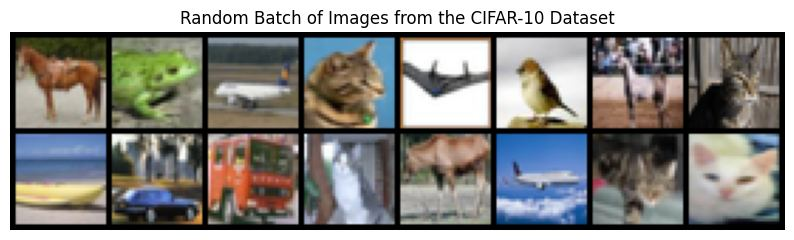

In [5]:
dataiter = iter(CIFAR_10_trainloader)
images, _ = next(dataiter)
imshow(torchvision.utils.make_grid(images[0:16]), "CIFAR-10")

<hr>

## <h1><b> Data Visualisation |<span style="color: #9370DB;"> MINST</span></b></h1>  

<hr>

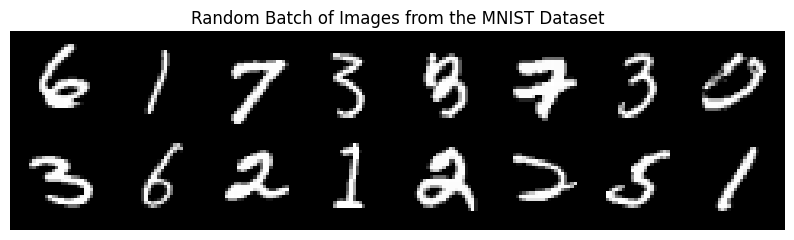

In [6]:
dataiter = iter(MNIST_trainloader)
images, _ = next(dataiter)
imshow(torchvision.utils.make_grid(images[0:16]), "MNIST")

<hr>

## <h1><b> Data Visualisation |<span style="color: #9370DB;"> MINST - Noisy</span></b></h1>  

<hr>

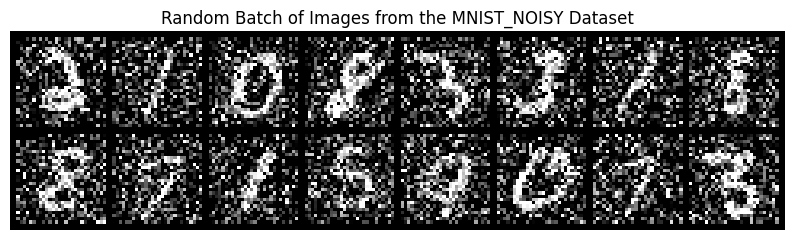

In [7]:
dataiter = iter(MNIST_trainloader_noisy)
images, _ = next(dataiter)
imshow(torchvision.utils.make_grid(images[0:16]), "MNIST_NOISY")

<hr>

## <h1><b> Saving Results |<span style="color: #9370DB;"> JSON File Format</span></b></h1>  

<hr>

In [8]:
# ✏️ ENTER ROLL NUMBER HERE
ROLL_NUMBER = "27100162"

RESULTS_FILE = f"{ROLL_NUMBER}_Overall_Results.json"

Overall_Results = {
    "Task 1": {
        "Train Loss (Last Epoch)": "",
        "Test Loss (Last Epoch)": "",
        "Train Loss (Minimum)": "",
        "Test Loss (Minimum)": ""
    },
    "Task 2": {
        "Train Loss (Last Epoch)": "",
        "Test Loss (Last Epoch)": "",
        "Train Loss (Minimum)": "",
        "Test Loss (Minimum)": ""
    },
    "Task 3": {
        "Train Loss (Last Epoch)": "",
        "Test Loss (Last Epoch)": "",
        "Train Loss (Minimum)": "",
        "Test Loss (Minimum)": ""
    },
    "Task 4": {
        "Train Loss (Last Epoch)": "",
        "Test Loss (Last Epoch)": "",
        "Train Loss (Minimum)": "",
        "Test Loss (Minimum)": ""
    },
    "Task 5": {
        "Train Loss (Last Epoch)": "",
        "Train Accuracy (Last Epoch)": "",
        "Test Loss (Original Dataset)": "",
        "Test Accuracy (Original Dataset)": "",
        "Test Precision (Original Dataset)": "",
        "Test Recall (Original Dataset)": "",
        "Test F1 Score (Original Dataset)": "",
        "Test Loss (LAERecon Dataset)": "",
        "Test Accuracy (LAERecon Dataset)": "",
        "Test Precision (LAERecon Dataset)": "",
        "Test Recall (LAERecon Dataset)": "",
        "Test F1 Score (LAERecon Dataset)": "",
        "Test Loss (CAERecon Dataset)": "",
        "Test Accuracy (CAERecon Dataset)": "",
        "Test Precision (CAERecon Dataset)": "",
        "Test Recall (CAERecon Dataset)": "",
        "Test F1 Score (CAERecon Dataset)": ""
    },
    "Task 6": {
        "Train Loss (Last Epoch)": "",
        "Train Accuracy (Last Epoch)": "",
        "Test Loss (Original Dataset)": "",
        "Test Accuracy (Original Dataset)": "",
        "Test Precision (Original Dataset)": "",
        "Test Recall (Original Dataset)": "",
        "Test F1 Score (Original Dataset)": "",
        "Test Loss (LAEDenoise Dataset)": "",
        "Test Accuracy (LAEDenoise Dataset)": "",
        "Test Precision (LAEDenoise Dataset)": "",
        "Test Recall (LAEDenoise Dataset)": "",
        "Test F1 Score (LAEDenoise Dataset)": "",
        "Test Loss (CAEDenoise Dataset)": "",
        "Test Accuracy (CAEDenoise Dataset)": "",
        "Test Precision (CAEDenoise Dataset)": "",
        "Test Recall (CAEDenoise Dataset)": "",
        "Test F1 Score (CAEDenoise Dataset)": ""
    }
}

with open(RESULTS_FILE, "w") as f:
    json.dump(Overall_Results, f, indent=4)

print("JSON created:", RESULTS_FILE)


JSON created: 27100162_Overall_Results.json


<hr>

## <h1 style="text-align: left;"><b>Task 1: Linear Autoencoder Reconstruction | <span style="color: #9370DB;">CIFAR-10</span></b></h1>

<hr>

### <h2>1. In a Linear Autoencoder (LAE):</h2>

<ul>
    <li>The <b>encoder</b> primarily uses <code>Linear</code> layers to compress the input into a lower-dimensional latent space.</li>
    <li>The <b>decoder</b> utilizes <code>Linear</code> layers to reconstruct the original input from the latent space.</li>
</ul>

<hr>

<h2>2. Fully Connected Layers in a Linear Autoencoder</h2>

<table border="1" cellpadding="10" cellspacing="0" width="100%">
    <tr style="background-color:rgb(60, 60, 60);">
        <th style="text-align: left;">Layer</th>
        <th style="text-align: left;">Function</th>
    </tr>
    <tr>
        <td><b>Linear</b></td>
        <td>Applies a fully connected transformation to project the input into a lower-dimensional space (encoding) or reconstruct it back (decoding).</td>
    </tr>
</table>

<p>You can read the PyTorch documentation as well for more information!</p>

<hr>

<h2>3. Understanding Linear Layers</h2>

<h3>Linear Layer</h3>
<p>A <b>Linear Layer</b> applies a fully connected transformation, mapping an input vector to an output vector using weights and biases.</p>
<p><b>Syntax:</b></p>
<pre style="background-color:rgb(60, 60, 60); padding: 10px; border-radius: 5px;">
nn.Linear(in_features, out_features)
</pre>

<ul>
    <li><b>in_features:</b> Number of input features (e.g., flattened image pixels).</li>
    <li><b>out_features:</b> Number of output features (e.g., latent space dimension).</li>
</ul>

<hr>

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">Linear Autoencoder</span></h1>

<hr>

In [9]:
class LinearAutoencoderRecon(nn.Module):
    def __init__(self):
        super(LinearAutoencoderRecon, self).__init__()
        # ===================== YOUR CODE HERE ======================
        self.encoder = nn.Sequential( #encoder
            nn.Flatten(), #flat
            nn.Linear(3 * 32 * 32, 1024), #fc1
            nn.ReLU(), #relu
            nn.Linear(1024, 256), #fc2
            nn.ReLU(), #relu2
            nn.Linear(256, 64) #latent64
        ) #endenc
          # kindly ignore comments i like to add next to each line to understand
        self.decoder = nn.Sequential( #decoder
            nn.Linear(64, 256), #fc3
            nn.ReLU(), #relu3
            nn.Linear(256, 1024), #fc4
            nn.ReLU(), #relu4
            nn.Linear(1024, 3 * 32 * 32), #fc5
            #nn.ReLU(), #relu4
            nn.Sigmoid() #0to1
        ) #enddec
        # ===========================================================
        #raise NotImplementedError

    def forward(self, x):
        # ===================== YOUR CODE HERE ======================
        z = self.encoder(x) #compress
        out = self.decoder(z) #rebuild
        out = out.view(-1, 3, 32, 32) #reshape
        return out
        # ===========================================================
        #raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">LAERecon</span></h1>

<hr>

### <p><strong>Overview:</strong><br>
The <code>LAERecon</code> is a class designed to facilitate the training, evaluation, and visualization of a <strong>Linear Autoencoder (LAE)</strong> model. It manages the training loop, computes losses, performs evaluations, and visualizes reconstructions to monitor model performance. The class also includes methods for saving and loading the model.</p>

---

<h3>Constructor (<code>__init__</code>):</h3>
<p>The constructor initializes key components:</p>
<ul>
  <li><code>model (nn.Module)</code>: The Linear Autoencoder model.</li>
  <li><code>train_loader (DataLoader)</code>: The training dataset loader.</li>
  <li><code>test_loader (DataLoader)</code>: The test dataset loader.</li>
  <li><code>lr (float)</code>: Learning rate for the optimizer (default <code>0.001</code>).</li>
  <li><code>num_epochs (int)</code>: Number of training epochs (default <code>20</code>).</li>
  <li><code>device (str or None)</code>: Device for computation (auto-detects if set to <code>None</code>).</li>
  <li><code>imshow_func (function or None)</code>: Optional function for visualizing reconstructions.</li>
</ul>

---

<h3>Methods:</h3>

<h4>1. Training (<code>train</code>)</h4>
<p><strong>Purpose:</strong> Trains the autoencoder over multiple epochs.</p>
<p><strong>Workflow:</strong> Iterates through training batches, performs a forward pass, computes loss, and updates weights using backpropagation. After each epoch, it evaluates the model and prints the training loss.</p>

<h4>2. Evaluation (<code>evaluate</code>)</h4>
<p><strong>Purpose:</strong> Evaluates the trained model's performance on the test dataset.</p>
<p><strong>Workflow:</strong> The model is set to evaluation mode, and test loss is calculated by comparing reconstructed outputs to the original images.</p>

<h4>3. Model Saving (<code>save_model</code>)</h4>
<p><strong>Purpose:</strong> Saves the trained model to a specified file path.</p>
<p><strong>Outputs:</strong> Prints a confirmation message upon saving.</p>

<h4>4. Model Loading (<code>load_model</code>)</h4>
<p><strong>Purpose:</strong> Loads a saved model from a specified file path.</p>
<p><strong>Outputs:</strong> Prints a confirmation message upon loading.</p>

<h4>5. Plotting Results (<code>plot_results</code>)</h4>
<p><strong>Purpose:</strong> Plots training and test losses over the epochs.</p>

<h4>6. Visualization of Reconstructions (<code>visualize_reconstructions</code>)</h4>
<p><strong>Purpose:</strong> Displays original and reconstructed images for model performance assessment.</p>

---

<h3>Example Usage:</h3>

```python
    # Instantiate the LAERecon class
    trainer = LAERecon(model, train_loader, test_loader, lr=0.001, num_epochs=20, device='cuda')

    # Start training
    trainer.train()

    # Plot training and test loss
    trainer.plot_results()

    # Visualize reconstructions
    trainer.visualize_reconstructions(num_images=5)
```

---

<h3>Summary:</h3>
<ul>
  <li>Handles training, evaluation, and visualization of a Linear Autoencoder.</li>
  <li>Supports model saving and loading.</li>
  <li>Provides loss tracking and reconstruction visualization.</li>
</ul>

<h3>Notes:</h3>
<ul>
  <li>Allows custom image visualization via <code>imshow_func</code>.</li>
  <li>Keeps track of loss trends for analysis.</li>
</ul>

In [10]:
class LAERecon:
    def __init__(self, model, train_loader, test_loader, lr=0.001, num_epochs=20, device=None, imshow_func=None):
        """
        Initializes the Linear Autoencoder Trainer.

        Args:
            model (nn.Module): The Autoencoder model.
            train_loader (DataLoader): Training dataset loader.
            test_loader (DataLoader): Test dataset loader.
            lr (float): Learning rate.
            num_epochs (int): Number of training epochs.
            device (str or None): 'mps' or 'cuda' or 'cpu', auto-detect if None.
            imshow_func (function or None): Function to visualize images (reconstructions).
        """
        self.name = "Linear Autoencoder (Reconstruction)"
        # ===================== YOUR CODE HERE =====================
        self.model = model.to(device)
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.lr = lr
        self.num_epochs = num_epochs
        self.device = device if device is not None else torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.imshow_func = imshow_func #vizfn

        self.criterion = nn.MSELoss() #mseloss
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr) #adamopt

        self.train_losses = []
        self.test_losses = []
        # ===========================================================

    def train(self):
        """
        Trains the Autoencoder for a specified number of epochs.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.train()
        for epoch in range(self.num_epochs):
            running_loss = 0.0
            for images, _ in self.train_loader: #batchloop
                images = images.to(self.device)

                self.optimizer.zero_grad() #zerograd
                outputs = self.model(images) #forward
                loss = self.criterion(outputs, images)
                loss.backward() #backprop
                self.optimizer.step() #update

                running_loss += loss.item() * images.size(0) #accum

            epoch_loss = running_loss / len(self.train_loader.dataset) #avg
            self.train_losses.append(epoch_loss)

            test_loss = self.evaluate(epoch, train=False)
            print(f"Epoch [{epoch+1}/{self.num_epochs}] Train Loss: {epoch_loss:.6f} Test Loss: {test_loss:.6f}") #log
        # ===========================================================
        #raise NotImplementedError

    def evaluate(self, epoch, train=True):
        """
        Evaluates the Autoencoder model on the test dataset after each epoch.

        Args:
            epoch (int): Current training epoch.
        """
        # ===================== YOUR CODE HERE ======================
        loader = self.train_loader if train else self.test_loader #pickL
        self.model.eval()
        running_loss = 0.0

        with torch.no_grad(): #nograd
            for images, _ in loader:
                images = images.to(self.device)
                outputs = self.model(images) #forward
                loss = self.criterion(outputs, images)
                running_loss += loss.item() * images.size(0)

        avg_loss = running_loss / len(loader.dataset) #avg
        if train:
            return avg_loss
        self.test_losses.append(avg_loss)
        #outputs = self.model(images) #forward
        #loss = self.criterion(outputs, images)
        return avg_loss
        # ===========================================================
        #raise NotImplementedError

    def save_model(self, path="/models/LAE_RECON.pth"):
        """
        Saves the trained model to a specified file path.

        Args:
            path (str): File path to save the model.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to: {path}")

    def load_model(self, path="/models/LAE_RECON.pth"):
        """
        Loads the trained model from a saved file.

        Args:
            path (str): File path of the saved model.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from: {path}")

    def plot_results(self):
        """
        Plots the training and test loss over epochs.
        """
        # ===================== YOUR CODE HERE ======================
        plt.figure(figsize=(8, 5))   # used aid from ai because i dont remmeber plottng syntx
        plt.plot(self.train_losses, label="Train Loss")
        plt.plot(self.test_losses, label="Test Loss") #test
        plt.xlabel("Epoch")
        plt.ylabel("loss ")
        plt.title(f"{self.name} Loss Curves")
        plt.legend()
        plt.grid(True)
        plt.show()
        # ===========================================================
        #raise NotImplementedError

    def visualize_reconstructions(self, num_images=5):
        """
        Visualizes the original and reconstructed images.

        Args:
            num_images (int): Number of images to display.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        dataiter = iter(self.test_loader)
        images, _ = next(dataiter)
        images = images.to(self.device)

        with torch.no_grad(): #nograd
            outputs = self.model(images)

        images_cpu = images[:num_images].cpu()
        outputs_cpu = outputs[:num_images].cpu()

        orig_grid = torchvision.utils.make_grid(images_cpu, nrow=num_images) #origgrid
        recon_grid = torchvision.utils.make_grid(outputs_cpu, nrow=num_images) #recongrid

        if self.imshow_func is not None:
            self.imshow_func(orig_grid, "Original")
            self.imshow_func(recon_grid, "Reconstructed")
        else:
            imshow(orig_grid, "Original")
            imshow(recon_grid, "Reconstructed")
        # ===========================================================
        #raise NotImplementedError

    def create_dataset(self):
        """
        Creates a dataset of reconstructed images for further analysis or classification.

        Returns:
            DataLoader: A DataLoader containing reconstructed images and labels.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        recon_images = []
        recon_labels = []

        with torch.no_grad():
            for images, labels in self.test_loader:
                images = images.to(self.device)
                outputs = self.model(images)
                recon_images.append(outputs.cpu())
                recon_labels.append(labels)

        recon_images = torch.cat(recon_images, dim=0) # cat img
        recon_labels = torch.cat(recon_labels, dim=0)#catlab

        recon_dataset = torch.utils.data.TensorDataset(recon_images, recon_labels)
        recon_loader = torch.utils.data.DataLoader(recon_dataset, batch_size=BATCH_SIZE, shuffle=False) #loader
        return recon_loader
        # ===========================================================
        #raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">LAE</span></h1>

<hr>

In [11]:
LAE_RECON_Model = LinearAutoencoderRecon()
LAE_RECON_Trainer =LAERecon(LAE_RECON_Model, CIFAR_10_trainloader, CIFAR_10_testloader, lr=LEARNING_RATE, num_epochs=EPOCHS, device=device, imshow_func=imshow) #trainer

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">LAE</span></h1>

<hr>

In [12]:
## ===================== YOUR CODE HERE ======================
LAE_RECON_Trainer.train()
# ===========================================================
##raise NotImplementedError stupid shit error

Epoch [1/10] Train Loss: 0.029354 Test Loss: 0.022561
Epoch [2/10] Train Loss: 0.020567 Test Loss: 0.018703
Epoch [3/10] Train Loss: 0.017414 Test Loss: 0.016855
Epoch [4/10] Train Loss: 0.016320 Test Loss: 0.015726
Epoch [5/10] Train Loss: 0.015129 Test Loss: 0.014765
Epoch [6/10] Train Loss: 0.014346 Test Loss: 0.013818
Epoch [7/10] Train Loss: 0.013529 Test Loss: 0.013266
Epoch [8/10] Train Loss: 0.013062 Test Loss: 0.012794
Epoch [9/10] Train Loss: 0.012691 Test Loss: 0.012625
Epoch [10/10] Train Loss: 0.012265 Test Loss: 0.012186


<hr>

### <h1 style="text-align: left;">Plot Results | <span style="color: #9370DB;">LAE</span></h1>

<hr>

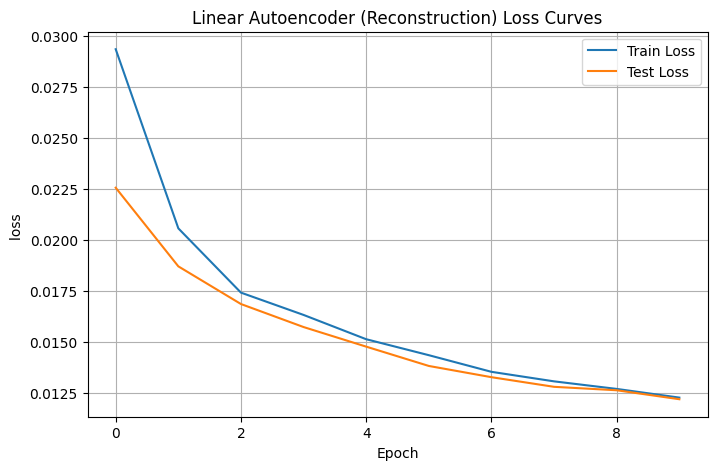

In [13]:
# ===================== YOUR CODE HERE ======================
LAE_RECON_Trainer.plot_results()
# ===========================================================
#raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Visualize Results | <span style="color: #9370DB;">LAE</span></h1>

<hr>

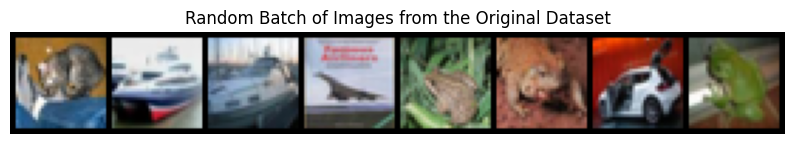

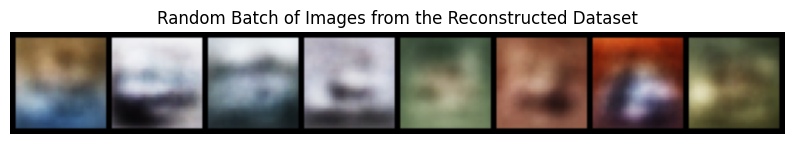

In [14]:
# ===================== YOUR CODE HERE ======================


LAE_RECON_Trainer.visualize_reconstructions(num_images=8) #showrecon

train_last = LAE_RECON_Trainer.train_losses[-1]
test_last = LAE_RECON_Trainer.test_losses[-1]
train_min = float(np.min(LAE_RECON_Trainer.train_losses))
test_min = float(np.min(LAE_RECON_Trainer.test_losses))

Overall_Results["Task 1"] = {
    "Train Loss (Last Epoch)": float(train_last),
    "Test Loss (Last Epoch)": float(test_last),
    "Train Loss (Minimum)": float(train_min),
    "Test Loss (Minimum)": float(test_min),
}


# ===========================================================
#raise NotImplementedError
# Update Overall_Results dictionary with actual values after training and evaluation
# Overall_Results["Task 1"] = {
#     "Train Loss (Last Epoch)": None,
#     "Test Loss (Last Epoch)": None,
#     "Train Loss (Minimum)": None,
#     "Test Loss (Minimum)": None,
# }

<hr>

### <h1 style="text-align: left;">Task 1 | <span style="color: #9370DB;">End</span></h1>

<hr>

<hr>

## <h1 style="text-align: left;"><b>Task 2: Convolutional Autoencoder Reconstruction | <span style="color: #9370DB;">CIFAR-10</span></b></h1>

<hr>


### <h2>1. In a Convolutional Autoencoder (CAE):</h2>

<ul>
    <li>The <b>encoder</b> primarily uses <code>Conv2d</code> and <code>MaxPool2d</code> layers for feature extraction and dimensionality reduction.</li>
    <li>The <b>decoder</b> utilizes <code>ConvTranspose2d</code> to upsample and reconstruct the original image.</li>
</ul>

<hr>

<h2>2. Convolutional Layers in a Convolutional Autoencoder</h2>

<table border="1" cellpadding="10" cellspacing="0" width="100%">
    <tr style="background-color:rgb(60, 60, 60);">
        <th style="text-align: left;">Layer</th>
        <th style="text-align: left;">Function</th>
    </tr>
    <tr>
        <td><b>Conv2d</b></td>
        <td>Extracts spatial features from the input image by applying filters.</td>
    </tr>
    <tr>
        <td><b>MaxPool2d</b></td>
        <td>Downsamples feature maps to reduce spatial dimensions while preserving key information.</td>
    </tr>
    <tr>
        <td><b>ConvTranspose2d</b></td>
        <td>Upsamples the compressed feature maps to reconstruct the original image.</td>
    </tr>
</table>

<p>You can read the PyTorch documentation aswell for more information!</p>

<hr>

<h2>3. Understanding Conv2d and ConvTranspose2d</h2>

<h3>Conv2d</h3>
<p>A <b>2D Convolutional Layer</b> applies filters (kernels) to the input image to extract spatial patterns such as edges and textures.</p>
<p><b>Syntax:</b></p>
<pre style="background-color:rgb(60, 60, 60); padding: 10px; border-radius: 5px;">
nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
</pre>

<ul>
    <li><b>in_channels:</b> Number of input channels (e.g., 3 for RGB images).</li>
    <li><b>out_channels:</b> Number of filters applied to extract features.</li>
    <li><b>kernel_size:</b> Size of the filter (e.g., 3×3).</li>
    <li><b>stride:</b> Step size for moving the filter across the image.</li>
    <li><b>padding:</b> Adds zero-padding to maintain spatial dimensions.</li>
</ul>

<h3>ConvTranspose2d</h3>
<p>The <b>ConvTranspose2d</b> layer performs the reverse operation of <b>Conv2d</b>, increasing the spatial dimensions of the feature maps.</p>
<p><b>Syntax:</b></p>
<pre style="background-color:rgb(60, 60, 60); padding: 10px; border-radius: 5px;">
nn.ConvTranspose2d(in_channels, out_channels, kernel_size, stride, padding)
</pre>

<ul>
    <li><b>in_channels:</b> Number of channels from the latent space.</li>
    <li><b>out_channels:</b> Number of filters used to reconstruct the image.</li>
    <li><b>kernel_size:</b> Size of the upsampling filter.</li>
    <li><b>stride:</b> Determines how much the feature maps expand.</li>
    <li><b>padding:</b> Adjusts spatial dimensions for accurate reconstruction.</li>
</ul>

<hr>

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">Convolutional AutoEncoder</span></h1>

<hr>

In [15]:
class ConvolutionalAutoencoderRecon(nn.Module):
    def __init__(self):
        super(ConvolutionalAutoencoderRecon, self).__init__()
        # ===================== YOUR CODE HERE =====================

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),  #conv1
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1),  #backrgb
            #nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid())

        # ===========================================================

    def forward(self, x):
        # ===================== YOUR CODE HERE =====================

        x =self.decoder(self.encoder(x))

        # ===========================================================
        return x

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">CAERecon</span></h1>

<hr>

### <p><strong>Overview:</strong><br>
The <code>CAERecon</code> is a class designed to facilitate the training, evaluation, and visualization of a <strong>Convolutional Autoencoder (CAE)</strong> model. It handles the training loop, computes losses, performs model evaluations after each epoch, and enables visualization of reconstructions to monitor model progress. The class also provides methods to save and load the model at any point.</p>

---

<h3>Constructor (<code>__init__</code>):</h3>
<p>The constructor initializes key components for training, evaluation, and visualization:</p>
<ul>
  <li><code>model (nn.Module)</code>: The Autoencoder model to be trained.</li>
  <li><code>train_loader (DataLoader)</code>: The training dataset loader.</li>
  <li><code>test_loader (DataLoader)</code>: The test dataset loader.</li>
  <li><code>lr (float)</code>: Learning rate for the optimizer (default is <code>0.001</code>).</li>
  <li><code>num_epochs (int)</code>: Number of epochs for training (default is <code>20</code>).</li>
  <li><code>device (str or None)</code>: Specifies the device for computation (e.g., 'cuda', 'mps', 'cpu'). It auto-detects if set to <code>None</code>.</li>
  <li><code>imshow_func (function or None)</code>: An optional function for visualizing images (reconstructed outputs from the model). This allows for custom image visualization logic, if needed.</li>
</ul>
<p>The constructor sets up the model, loss function (<code>MSELoss</code>), optimizer (<code>Adam</code>), and prepares lists for storing training and test losses. It also prints a summary of the model.</p>

---

<h3>Methods:</h3>

<h4>1. Training (<code>train</code>)</h4>
<p><strong>Purpose:</strong> Trains the autoencoder model over a specified number of epochs.</p>
<p><strong>Workflow:</strong> Iterates over training data, performing a forward pass, calculating loss, and updating model weights using backpropagation. After every epoch, the method prints the training loss and calls the <code>evaluate</code> method to assess the model on the test dataset.</p>
<p><strong>Outputs:</strong> Prints the average training loss at the end of each epoch.</p>

<h4>2. Evaluation (<code>evaluate</code>)</h4>
<p><strong>Purpose:</strong> Evaluates the trained model's performance on the test dataset after each epoch.</p>
<p><strong>Workflow:</strong> The model is set to evaluation mode (<code>eval</code>), and predictions are made on the test set. The <strong>test loss</strong> is computed by comparing the model's outputs with the ground truth.</p>
<p><strong>Outputs:</strong> Prints the test loss for the current epoch.</p>

<h4>3. Model Saving (<code>save_model</code>)</h4>
<p><strong>Purpose:</strong> Saves the trained model to a file.</p>
<p><strong>Path:</strong> The model is saved to the provided path (default is <code>/models/cae_model.pth</code>).</p>
<p><strong>Outputs:</strong> Prints a message confirming the model has been saved to the specified path.</p>

<h4>4. Model Loading (<code>load_model</code>)</h4>
<p><strong>Purpose:</strong> Loads a pre-trained model from a file.</p>
<p><strong>Path:</strong> Loads the model from the specified path (default is <code>/models/cae_model.pth</code>).</p>
<p><strong>Outputs:</strong> Prints a message confirming the model has been loaded from the specified path.</p>

<h4>5. Plotting Results (<code>plot_results</code>)</h4>
<p><strong>Purpose:</strong> Plots the training and test losses over the course of training.</p>
<p><strong>Workflow:</strong> After training, this method visualizes the losses for both training and test sets over all epochs.</p>
<p><strong>Outputs:</strong> Displays a plot with two lines: one for <strong>training loss</strong> and one for <strong>test loss</strong>, enabling a comparison of performance.</p>

<h4>6. Visualization of Reconstructions (<code>visualize_reconstructions</code>)</h4>
<p><strong>Purpose:</strong> Visualizes the <strong>original images</strong> alongside their <strong>reconstructed outputs</strong> from the trained model.</p>
<p><strong>Workflow:</strong> The model is set to evaluation mode (<code>eval</code>). A batch of test images is passed through the model to obtain reconstructions. A few images (specified by <code>num_images</code>) are displayed, where the first image in each pair is the ground truth and the second is the reconstruction.</p>
<p><strong>Outputs:</strong> Displays side-by-side visualizations of original and reconstructed images for comparison.</p>

---

<h3>Example Usage:</h3>

```python
# Instantiate the CAERecon class
trainer = CAERecon(model, train_loader, test_loader, lr=0.001, num_epochs=20, device='cuda')

# Start training
trainer.train()

# After training, plot the training and test losses
trainer.plot_results()

# Visualize the reconstructions from the test set
trainer.visualize_reconstructions(num_images=5)
```

---

<h3>Summary:</h3>
<p>The <code>CAERecon</code> class provides an end-to-end solution for training a <strong>Convolutional Autoencoder (CAE)</strong> model. It includes methods for:</p>
<ul>
  <li>Training and loss calculation</li>
  <li>Periodic evaluation and printing of test losses</li>
  <li>Visualizing reconstructed images alongside ground truth</li>
  <li>Saving and loading model weights</li>
</ul>
<p>This structure helps you monitor the model's progress at each epoch, assess performance, and visualize the model's reconstructions in a streamlined manner.</p>

---

<h3>Notes:</h3>
<ul>
  <li>The class is designed to be flexible and can accept a custom image visualization function (<code>imshow_func</code>) for visualizing the model's reconstructions.</li>
  <li>Loss values are tracked during training and evaluation for both training and test sets, enabling meaningful analysis of model performance over time.</li>
</ul>

In [16]:
class CAERecon:
    def __init__(self, model, train_loader, test_loader, lr=0.001, num_epochs=20, device=None, imshow_func=None):
        """
        Initializes the Convolutional Autoencoder Trainer.

        Args:
            model (nn.Module): The Autoencoder model.
            train_loader (DataLoader): Training dataset loader.
            test_loader (DataLoader): Test dataset loader.
            lr (float): Learning rate.
            num_epochs (int): Number of training epochs.
            device (str or None): 'mps' or 'cuda' or 'cpu', auto-detect if None.
            imshow_func (function or None): Function to visualize images (reconstructions).
        """
        self.name = "Convolutional Autoencoder (Reconstruction)"
        # ===================== YOUR CODE HERE =====================
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.lr = lr
        self.num_epochs = num_epochs
        self.device = device if device is not None else torch.device("cuda" if torch.cuda.is_available() else "cpu")  #autodev
        self.imshow_func = imshow_func
        self.model.to(self.device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)  #adam
        self.train_losses = []
        self.test_losses = []
        try:
            summary(self.model, (3, 32, 32))
        except:
            pass
        # ===========================================================

    def train(self):
        """
        Trains the Autoencoder for a specified number of epochs.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.train()
        for epoch in range(self.num_epochs):
            running_loss = 0.0  #sum
            for images, _ in self.train_loader:
                images = images.to(self.device)
                self.optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(outputs, images)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * images.size(0)

            epoch_loss = running_loss / len(self.train_loader.dataset)
            self.train_losses.append(epoch_loss)
            test_loss = self.evaluate(epoch, train=False)
            print(f"Epoch [{epoch+1}/{self.num_epochs}] Train Loss: {epoch_loss:.6f} Test Loss: {test_loss:.6f}")
        # ===========================================================
        #raise NotImplementedError

    def evaluate(self, epoch, train=True):
        """
        Evaluates the Autoencoder model on the test dataset after each epoch.

        Args:
            epoch (int): Current training epoch.
        """
        # ===================== YOUR CODE HERE ======================
        loader = self.train_loader if train else self.test_loader
        self.model.eval()
        running_loss = 0.0
        with torch.no_grad():
            for images, _ in loader:
                images = images.to(self.device)
                outputs = self.model(images)
                loss = self.criterion(outputs, images)
                running_loss += loss.item() * images.size(0)
        avg_loss = running_loss /len(  loader.dataset)
        if train:
            return avg_loss
        self.test_losses.append(avg_loss)  #store
        return avg_loss
        # ===========================================================
        #raise NotImplementedError

    def save_model(self, path="/models/CAE_RECON.pth"):
        """
        Saves the trained model to a specified file path.

        Args:
            path (str): File path to save the model.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to: {path}")

    def load_model(self, path="/models/CAE_RECON.pth"):
        """
        Loads the trained model from a saved file.

        Args:
            path (str): File path of the saved model.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from: {path}")

    def plot_results(self):
        """
        Plots the training and test loss over epochs.
        """
        # ===================== YOUR CODE HERE ======================
        plt.figure(figsize=(8, 5))
        plt.plot(self.train_losses, label="Train Loss")  #train
        plt.plot(self.test_losses, label="Test Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(f"{self.name} Loss curves")
        plt.legend()
        plt.grid(True)
        plt.show()
        # ===========================================================
        #raise NotImplementedError

    def visualize_reconstructions(self, num_images=5):
        """
        Visualizes the original and reconstructed images.

        Args:
            num_images (int): Number of images to display.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        dataiter = iter(self.test_loader)
        images, _ = next(dataiter)  #batch
        images = images.to(self.device)
        with torch.no_grad():
            outputs = self.model(images)
        images_cpu = images[:num_images].cpu()
        outputs_cpu = outputs[:num_images].cpu()
        orig_grid = torchvision.utils.make_grid(images_cpu, nrow=num_images)
        recon_grid = torchvision.utils.make_grid(outputs_cpu, nrow=num_images)  #grid
        if self.imshow_func is not None:
            self.imshow_func(orig_grid, "Original")
            self.imshow_func(recon_grid, "Reconstructed")
        else:
            imshow(orig_grid, "Original")
            imshow(recon_grid, "Reconstructed")
            #self.imshow_func(recon_grid, "Reconstructed")
        # ===========================================================
        #raise NotImplementedError

    def create_dataset(self):
        """
        Creates a dataset of reconstructed images for further analysis or classification.

        Returns:
            DataLoader: A DataLoader containing reconstructed images and labels.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        recon_images = []
        recon_labels = []  #labels
        with torch.no_grad():
            for images, labels in self.test_loader:
                images = images.to(self.device)
                outputs = self.model(images)
                recon_images.append(outputs.cpu())
                recon_labels.append(labels)

        recon_images = torch.cat(recon_images, dim=0)
        recon_labels = torch.cat(recon_labels, dim=0)
        recon_dataset = torch.utils.data.TensorDataset(recon_images, recon_labels)
        recon_loader = torch.utils.data.DataLoader(recon_dataset, batch_size=BATCH_SIZE, shuffle=False)
        return recon_loader  #done ezzz
        # ===========================================================
        ######## bro raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">CAE</span></h1>

<hr>

In [17]:
CAE_RECON_Model =ConvolutionalAutoencoderRecon()
CAE_RECON_Trainer =CAERecon(CAE_RECON_Model, CIFAR_10_trainloader, CIFAR_10_testloader, lr=LEARNING_RATE, num_epochs=EPOCHS, device=None, imshow_func=imshow)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 32, 32]             896
              ReLU-2           [-1, 32, 32, 32]               0
         MaxPool2d-3           [-1, 32, 16, 16]               0
            Conv2d-4           [-1, 64, 16, 16]          18,496
              ReLU-5           [-1, 64, 16, 16]               0
         MaxPool2d-6             [-1, 64, 8, 8]               0
            Conv2d-7            [-1, 128, 8, 8]          73,856
              ReLU-8            [-1, 128, 8, 8]               0
         MaxPool2d-9            [-1, 128, 4, 4]               0
  ConvTranspose2d-10             [-1, 64, 8, 8]          73,792
             ReLU-11             [-1, 64, 8, 8]               0
  ConvTranspose2d-12           [-1, 32, 16, 16]          18,464
             ReLU-13           [-1, 32, 16, 16]               0
  ConvTranspose2d-14            [-1, 3,

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">CAE</span></h1>

<hr>

In [18]:
# ===================== YOUR CODE HERE ======================
CAE_RECON_Trainer.train()
# ===========================================================
#raise NotImplementedError

Epoch [1/10] Train Loss: 0.018857 Test Loss: 0.011203
Epoch [2/10] Train Loss: 0.010083 Test Loss: 0.009892
Epoch [3/10] Train Loss: 0.008663 Test Loss: 0.008119
Epoch [4/10] Train Loss: 0.007701 Test Loss: 0.007040
Epoch [5/10] Train Loss: 0.006895 Test Loss: 0.006524
Epoch [6/10] Train Loss: 0.006434 Test Loss: 0.006199
Epoch [7/10] Train Loss: 0.006138 Test Loss: 0.005903
Epoch [8/10] Train Loss: 0.005879 Test Loss: 0.005685
Epoch [9/10] Train Loss: 0.005675 Test Loss: 0.005543
Epoch [10/10] Train Loss: 0.005489 Test Loss: 0.005339


<hr>

### <h1 style="text-align: left;">Plot Results | <span style="color: #9370DB;">CAE</span></h1>

<hr>

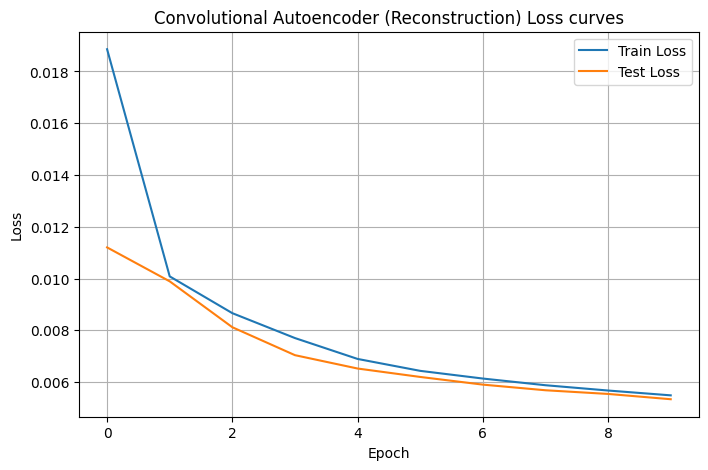

In [19]:
# ===================== YOUR CODE HERE ======================
CAE_RECON_Trainer.plot_results()
# ===========================================================
#raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Visualize Results | <span style="color: #9370DB;">CAE</span></h1>

<hr>

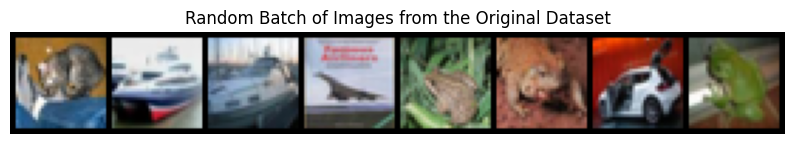

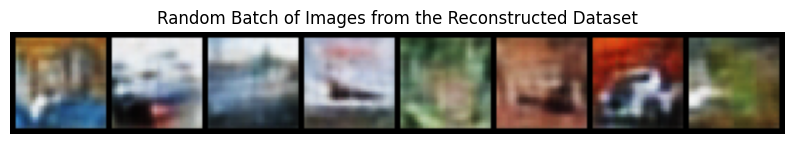

In [20]:
# ===================== YOUR CODE HERE ======================
CAE_RECON_Trainer.visualize_reconstructions(num_images=8)

train_last = CAE_RECON_Trainer.train_losses[-1]
test_last = CAE_RECON_Trainer.test_losses[-1]  #last
train_min = float(np.min(CAE_RECON_Trainer.train_losses))
test_min = float(np.min(CAE_RECON_Trainer.test_losses))

Overall_Results["Task 2"] = {
    "Train Loss (Last Epoch)": float(train_last),
    "Test Loss (Last Epoch)": float(test_last),
    "Train Loss (Minimum)": float(train_min),  #min
    "Test Loss (Minimum)": float(test_min),
}
# ===========================================================
#raise NotImplementedError
# Update Overall_Results dictionary with actual values after training and evaluation
# Overall_Results["Task 2"] = {
#     "Train Loss (Last Epoch)": None,
#     "Test Loss (Last Epoch)": None,
#     "Train Loss (Minimum)": None,
#     "Test Loss (Minimum)": None,
# }

<hr>

## <h1 style="text-align: left;"><b>Task 3: Linear Autoencoder Denoising | <span style="color: #9370DB;">MNIST</span></b></h1>

<hr>

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">Linear Autoencoder</span></h1>

<hr>

In [21]:
class LinearAutoencoderDenoise(nn.Module):
    def __init__(self):
        super(LinearAutoencoderDenoise, self).__init__()
        # ===================== YOUR CODE HERE =====================

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 256),  #fc1
            nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(),nn.Linear(64, 32))

        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),  #relu
            #nn.Linear(64, 32)
            nn.Linear(256, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)))

        # ===========================================================

    def forward(self, x):
        # ===================== YOUR CODE HERE =====================

        x =  self.decoder(self.encoder(x))

        # ===========================================================
        return x

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">LAEDenoise</span></h1>

<hr>

In [22]:
class LAEDenoise:
    def __init__(self, model, train_loader, test_loader, lr=0.001, num_epochs=20, device=None, imshow_func=None):
        """
        Initializes the Linear Autoencoder Trainer for Denoising.

        Args:
            model (nn.Module): The Autoencoder model.
            train_loader (DataLoader): Training dataset loader.
            test_loader (DataLoader): Test dataset loader.
            lr (float): Learning rate.
            num_epochs (int): Number of training epochs.
            device (str or None): 'mps' or 'cuda' or 'cpu', auto-detect if None.
            imshow_func (function or None): Function to visualize images (denoised reconstructions).
        """
        self.name = "Linear Autoencoder (Denoising)"
        # ===================== YOUR CODE HERE =====================
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.lr = lr
        self.num_epochs = num_epochs
        self.device = device if device is not None else torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.imshow_func = imshow_func  #viz
        self.model.to(self.device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)

        self.train_losses = []
        self.test_losses = []
        # ===========================================================

    def train(self):
        """
        Trains the Autoencoder for a specified number of epochs.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.train()
        for epoch in range(self.num_epochs):
            running_loss = 0.0
            for clean, _ in self.train_loader:
                clean = clean.to(self.device)
                noisy = torch.clamp(clean + 0.5 * torch.randn_like(clean), 0.0, 1.0)  #addnoise

                self.optimizer.zero_grad()
                outputs = self.model(noisy)
                loss = self.criterion(outputs, clean)
                loss.backward()
                self.optimizer.step()

                running_loss += loss.item() * clean.size(0)

            epoch_loss = running_loss / len(self.train_loader.dataset)
            self.train_losses.append(epoch_loss)

            test_loss = self.evaluate(epoch, train=False)
            print(f"Epoch [{epoch+1}/{self.num_epochs}] Train Loss: {epoch_loss:.6f} Test loss: {test_loss:.6f}")
        # ===========================================================
        #raise NotImplementedError

    def evaluate(self, epoch, train=True):
        """
        Evaluates the Autoencoder model on the test dataset after each epoch.

        Args:
            epoch (int): Current training epoch.
        """
        # ===================== YOUR CODE HERE ======================
        loader = self.train_loader if train else self.test_loader
        self.model.eval()
        running_loss = 0.0
        with torch.no_grad():
            for clean, _ in loader:
                clean = clean.to(self.device)
                noisy = torch.clamp(clean + 0.5 * torch.randn_like(clean), 0.0, 1.0)
                outputs = self.model(noisy)
                loss = self.criterion(outputs, clean)
                running_loss += loss.item() * clean.size(0)  #sum

        avg_loss = running_loss / len(loader.dataset)
        if train:
            return avg_loss
        self.test_losses.append(avg_loss)
        return avg_loss
        # ===========================================================
        #raise NotImplementedError

    def save_model(self, path="/models/LAE_DENOISE.pth"):
        """
        Saves the trained model to a specified file path.

        Args:
            path (str): File path to save the model.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to: {path}")

    def load_model(self, path="/models/LAE_DENOISE.pth"):
        """
        Loads the trained model from a saved file.

        Args:
            path (str): File path of the saved model.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from: {path}")

    def plot_results(self):
        """
        Plots the training and test loss over epochs.
        """
        # ===================== YOUR CODE HERE =====================
        plt.figure(figsize=(8, 5))
        plt.plot(self.train_losses, label="Train Loss")
        plt.plot(self.test_losses, label="Test Loss")  #test
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(f"{self.name} Loss Curves")
        plt.legend()
        plt.grid(True)
        plt.show()
        # ===========================================================
        #raise NotImplementedError

    def visualize_denoising(self, num_images=5):
        """
        Visualizes the original and denoised images.

        Args:
            num_images (int): Number of images to display.
        """
        # ===================== YOUR CODE HERE =====================
        self.model.eval()
        dataiter = iter(self.test_loader)
        clean, _ = next(dataiter)
        clean = clean.to(self.device)
        noisy = torch.clamp(clean + 0.5 * torch.randn_like(clean), 0.0, 1.0)  #noise
        with torch.no_grad():
            denoised = self.model(noisy)
        clean_cpu = clean[:num_images].cpu()
        noisy_cpu = noisy[:num_images].cpu()
        denoised_cpu = denoised[:num_images].cpu()
        noisy_grid = torchvision.utils.make_grid(noisy_cpu, nrow=num_images)
        den_grid = torchvision.utils.make_grid(denoised_cpu, nrow=num_images)
        clean_grid = torchvision.utils.make_grid(clean_cpu, nrow=num_images)

        if self.imshow_func is not None:
            self.imshow_func(noisy_grid, "Noisy")
            self.imshow_func(den_grid, "Denoised")
            self.imshow_func(clean_grid, "Clean")  #gt
        else:
            imshow(noisy_grid, "Noisy")
            imshow(den_grid, "Denoised")
            imshow(clean_grid, "Clean")

        #noisy_cpu = noisy[:num_images].cpu()
        #clean_grid = torchvision.
        # ===========================================================
        #raise NotImplementedError

    def create_dataset(self):
        """
        Creates a dataset of reconstructed images for further analysis or classification.

        Returns:
            DataLoader: A DataLoader containing reconstructed images and labels.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        den_images = []
        den_labels = []

        with torch.no_grad():
            for clean, labels in self.test_loader:
                clean = clean.to(self.device)
                noisy = torch.clamp(clean + 0.5 * torch.randn_like(clean), 0.0, 1.0)
                outputs = self.model(noisy)
                den_images.append(outputs.cpu())  #store
                den_labels.append(labels)

        den_images = torch.cat(den_images, dim=0)
        den_labels = torch.cat(den_labels, dim=0)

        den_dataset = torch.utils.data.TensorDataset(den_images, den_labels)
        den_loader = torch.utils.data.DataLoader(den_dataset, batch_size=BATCH_SIZE, shuffle=False)
        return den_loader
        # ===========================================================
        #raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">LAE</span></h1>

<hr>

In [23]:
LAE_DENOISE_Model =LinearAutoencoderDenoise()
LAE_DENOISE_Trainer = LAEDenoise(LAE_DENOISE_Model, MNIST_trainloader, MNIST_testloader, lr=LEARNING_RATE, num_epochs=EPOCHS, device=None, imshow_func=imshow)

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">LAE</span></h1>

<hr>

In [24]:
# ===================== YOUR CODE HERE ======================
LAE_DENOISE_Trainer.train()
# ===========================================================
#raise NotImplementedError

Epoch [1/10] Train Loss: 0.063180 Test loss: 0.045640
Epoch [2/10] Train Loss: 0.037389 Test loss: 0.033212
Epoch [3/10] Train Loss: 0.030966 Test loss: 0.028726
Epoch [4/10] Train Loss: 0.027734 Test loss: 0.026568
Epoch [5/10] Train Loss: 0.025501 Test loss: 0.024155
Epoch [6/10] Train Loss: 0.023753 Test loss: 0.022635
Epoch [7/10] Train Loss: 0.022487 Test loss: 0.021371
Epoch [8/10] Train Loss: 0.021488 Test loss: 0.020704
Epoch [9/10] Train Loss: 0.020715 Test loss: 0.019895
Epoch [10/10] Train Loss: 0.020038 Test loss: 0.019557


<hr>

### <h1 style="text-align: left;">Plot Results | <span style="color: #9370DB;">LAE</span></h1>

<hr>

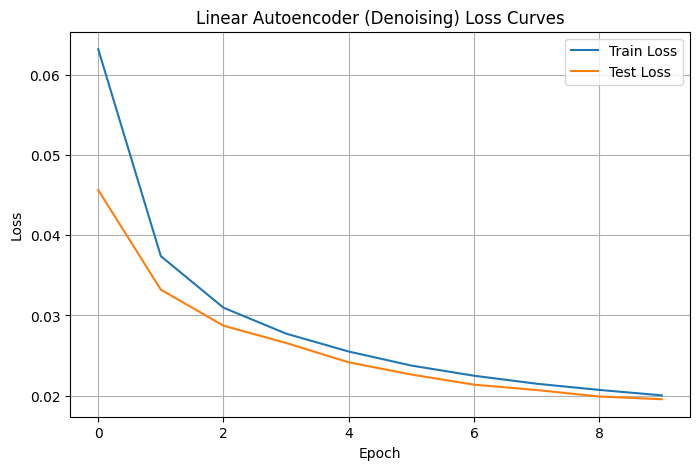

In [25]:
# ===================== YOUR CODE HERE ======================
LAE_DENOISE_Trainer.plot_results()
# ===========================================================
#raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Visualize Results | <span style="color: #9370DB;">LAE</span></h1>

<hr>

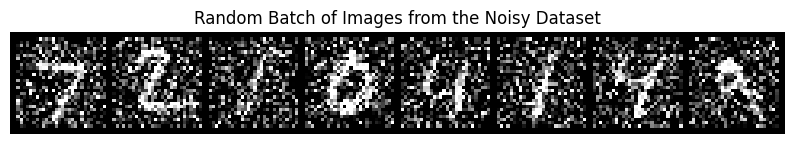

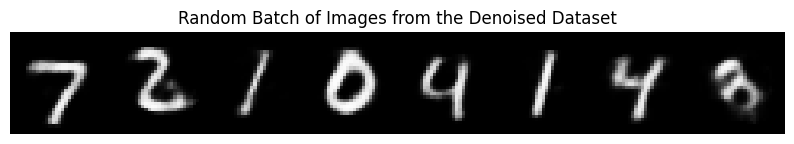

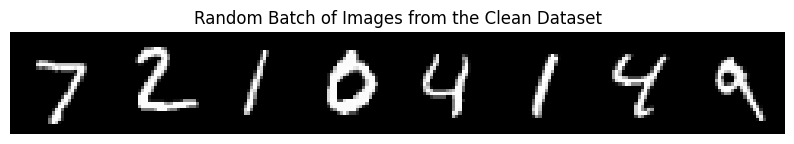

In [26]:
# ===================== YOUR CODE HERE ======================
LAE_DENOISE_Trainer.visualize_denoising(num_images=8)

train_last = LAE_DENOISE_Trainer.train_losses[-1]
test_last = LAE_DENOISE_Trainer.test_losses[-1]
train_min = float(np.min(LAE_DENOISE_Trainer.train_losses))
test_min = float(np.min(LAE_DENOISE_Trainer.test_losses))
Overall_Results["Task 3"] = {
    "Train Loss (Last Epoch)": float(train_last),
    "Test Loss (Last Epoch)": float(test_last),
    "Train Loss (Minimum)": float(train_min),
    "Test Loss (Minimum)": float(test_min),
}
# ===========================================================
#raise NotImplementedError
# Update Overall_Results dictionary with actual values after training and evaluation
# Overall_Results["Task 3"] = {
#     "Train Loss (Last Epoch)": None,
#     "Test Loss (Last Epoch)": None,
#     "Train Loss (Minimum)": None,
#     "Test Loss (Minimum)": None,
# }

<hr>

### <h1 style="text-align: left;">Task 3 | <span style="color: #9370DB;">End</span></h1>

<hr>

<hr>

## <h1 style="text-align: left;"><b>Task 4: Convolutional Autoencoder Denoising | <span style="color: #9370DB;">MNIST</span></b></h1>

<hr>

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">Convolutional AutoEncoder</span></h1>

<hr>

In [27]:
class ConvolutionalAutoencoderDenoise(nn.Module):
    def __init__(self):
        super(ConvolutionalAutoencoderDenoise, self).__init__()
        # ===================== YOUR CODE HERE ======================
        self.encoder = nn.Sequential(
            # nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1),
            # nn.ReLU(),
            # nn.MaxPool2d(2, 2),  #14
            # nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            # nn.MaxPool2d(2, 2),  #7
            #  nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.ReLU())
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.1, inplace=True),
            nn.MaxPool2d(2, 2),   # 28 -> 14

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.1, inplace=True),
            nn.MaxPool2d(2, 2),   # 14 -> 7

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.1, inplace=True),
            )


        self.decoder = nn.Sequential(
            # nn.ConvTranspose2d(64, 32, kernel_size=3, stride=1, padding=1),
            # nn.ReLU(),
            # nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            # nn.ReLU(),
            # nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),  #back1
            # nn.Sigmoid())
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),  # 7 -> 14
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.1, inplace=True),

            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),   # 14 -> 28
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.1, inplace=True),

            nn.Conv2d(32, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
              )


        # ===========================================================
     #   raise NotImplementedError

    def forward(self, x):
        # ===================== YOUR CODE HERE ======================
        x = self.encoder(x)
        x = self.decoder(x)
        return x # HOLY HELL I FORGOT THIS DAMN LINE . OH MY GOD
        # ===========================================================
        #raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">CAEDenoise</span></h1>

<hr>

In [34]:
class CAEDenoise:
    def __init__(self, model, train_loader, test_loader, lr=0.001, num_epochs=20, device=None, imshow_func=None, noise_std = 0.5):
        """
        Initializes the Convolutional Autoencoder Trainer for Denoising.

        Args:
            model (nn.Module): The Autoencoder model.
            train_loader (DataLoader): Training dataset loader.
            test_loader (DataLoader): Test dataset loader.
            lr (float): Learning rate.
            num_epochs (int): Number of training epochs.
            device (str or None): 'mps' or 'cuda' or 'cpu', auto-detect if None.
            imshow_func (function or None): Function to visualize images (denoised reconstructions).
        """
        self.name = "Convolutional Autoencoder (Denoising)"
        # ===================== YOUR CODE HERE ======================
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.lr = lr
        self.num_epochs = num_epochs
        self.noise_std = noise_std
        self.device = device if device is not None else torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.imshow_func = imshow_func
        self.model.to(self.device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)
        self.train_losses = []
        self.test_losses = []
        # ===========================================================
        # raise NotImplementedError
        # self.train_loader = train_loader
        # self.test_loader = test_loader
        # self.lr = lr
        # self.num_epochs = num_epochs
    def train(self):
        """
        Trains the Autoencoder for a specified number of epochs.
        """
        # ===================== YOUR CODE HERE ======================
       # self.model.train()
        for epoch in range(self.num_epochs):
            self.model.train()
            running_loss = 0.0
            #for
            for clean, _ in self.train_loader:
                clean = clean.to(self.device)
                noisy = clean + self.noise_std*torch.randn_like(clean)
                noisy = torch.clamp(noisy, 0.0, 1.0)
                self.optimizer.zero_grad()
                outputs = self.model(noisy)
                loss = self.criterion(outputs, clean)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * clean.size(0)
            train_loss = running_loss / len(self.train_loader.dataset)
            self.train_losses.append(train_loss)
            test_loss = self.evaluate(train=False)
            print(f"Epoch [{epoch+1}/{self.num_epochs}] Train Loss: {train_loss:.6f} Test Loss: {test_loss:.6f}")
        # ===========================================================
        #raise NotImplementedError

    def evaluate(self, epoch = None, train=True):
        """
        Evaluates the Autoencoder model on the test dataset after each epoch.

        Args:
            epoch (int): Current training epoch.
        """
        # ===================== YOUR CODE HERE ======================
        loader = self.train_loader if train else self.test_loader
        self.model.eval()
        running_loss = 0.0
        with torch.no_grad():
            for clean, _ in loader:
                clean = clean.to(self.device)
                noisy=clean + self.noise_std*torch.randn_like(clean)
                noisy= torch.clamp(noisy, 0.0,1.0)
                outputs = self.model(noisy)
                loss = self.criterion(outputs, clean)
                running_loss +=loss.item()*clean.size(0)

        avg_loss = running_loss / len(loader.dataset)
        if not train:
            self.test_losses.append(avg_loss)
        return avg_loss
        # ===========================================================
        #raise NotImplementedError

    def save_model(self, path="/models/CAE_DENOISE.pth"):
        """
        Saves the trained model to a specified file path.

        Args:
            path (str): File path to save the model.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to: {path}")

    def load_model(self, path="/models/CAE_DENOISE.pth"):
        """
        Loads the trained model from a saved file.

        Args:
            path (str): File path of the saved model.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from: {path}")

    def plot_results(self):
        """
        Plots the training and test loss over epochs.
        """
        # ===================== YOUR CODE HERE =====================
        plt.figure(figsize=(8, 5))
        plt.plot(self.train_losses, label="Train Loss")
        plt.plot(self.test_losses, label="Test Loss")
        plt.xlabel("Epoch")  #x
        plt.ylabel("Loss")
        plt.title(f"{self.name} Loss Curves")
        plt.legend()
        plt.grid(True)
        plt.show()
        # ===========================================================
      #  raise NotImplementedError

    def visualize_denoising(self, num_images=5):
        """
        Visualizes the original and denoised images.

        Args:
            num_images (int): Number of images to display.
        """
        # ===================== YOUR CODE HERE =====================
        self.model.eval()
        dataiter = iter(self.test_loader)
        clean, _ = next(dataiter)
        clean = clean.to(self.device)
        noisy = torch.clamp(clean + 0.5*torch.randn_like(clean),0.0, 1.0)

        with torch.no_grad():
            denoised = self.model(noisy)  #den
        clean_cpu = clean[:num_images].cpu()
        noisy_cpu = noisy[:num_images].cpu()
        den_cpu = denoised[:num_images].cpu()
        noisy_grid = torchvision.utils.make_grid(noisy_cpu, nrow=num_images)
        den_grid = torchvision.utils.make_grid(den_cpu, nrow=num_images)
        clean_grid = torchvision.utils.make_grid(clean_cpu, nrow=num_images)

        if self.imshow_func is not None:
            self.imshow_func(noisy_grid, "Noisy")
            self.imshow_func(den_grid, "Denoised")
            self.imshow_func(clean_grid, "Clean")
        else:
            imshow(noisy_grid, "Noisy")
            imshow(den_grid, "Denoised")
            imshow(clean_grid, "Clean")
        # ===========================================================
        # OH MA GOD raise NotImplementedError

    def create_dataset(self):
        """
        Creates a dataset of reconstructed images for further analysis or classification.

        Returns:
            DataLoader: A DataLoader containing reconstructed images and labels.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        den_images = []
        den_labels = []
        with torch.no_grad():
            for clean, labels in self.test_loader:
                clean = clean.to(self.device)
                noisy = torch.clamp(clean + 0.5*torch.randn_like(clean),0.0, 1.0)  #noise
                outputs = self.model(noisy)
                den_images.append(outputs.cpu())
                den_labels.append(labels)
        den_images = torch.cat(den_images, dim=0)
        den_labels = torch.cat(den_labels, dim=0)
        den_dataset = torch.utils.data.TensorDataset(den_images, den_labels)
        den_loader = torch.utils.data.DataLoader(den_dataset, batch_size=BATCH_SIZE, shuffle=False)
        return den_loader
        # ===========================================================
        #raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">CAE</span></h1>

<hr>

In [35]:
CAE_DENOISE_Model = ConvolutionalAutoencoderDenoise()
CAE_DENOISE_Trainer =CAEDenoise(CAE_DENOISE_Model, MNIST_trainloader, MNIST_testloader, lr=LEARNING_RATE, num_epochs=EPOCHS, device=None, imshow_func=imshow, noise_std = 0.5)

In [36]:
# debug // params
# p = next(CAE_DENOISE_Trainer.model.parameters())
# print("param mean:", p.data.abs().mean().item())

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">CAE</span></h1>

<hr>

In [37]:
# ===================== YOUR CODE HERE ======================
CAE_DENOISE_Trainer.train()
# ===========================================================
#raise NotImplementedError

Epoch [1/10] Train Loss: 0.017434 Test Loss: 0.011482
Epoch [2/10] Train Loss: 0.011101 Test Loss: 0.010702
Epoch [3/10] Train Loss: 0.010573 Test Loss: 0.010417
Epoch [4/10] Train Loss: 0.010295 Test Loss: 0.010187
Epoch [5/10] Train Loss: 0.010124 Test Loss: 0.010001
Epoch [6/10] Train Loss: 0.009942 Test Loss: 0.009998
Epoch [7/10] Train Loss: 0.009840 Test Loss: 0.009801
Epoch [8/10] Train Loss: 0.009792 Test Loss: 0.009804
Epoch [9/10] Train Loss: 0.009727 Test Loss: 0.009480
Epoch [10/10] Train Loss: 0.009667 Test Loss: 0.009549


In [38]:
#debug
CAE_DENOISE_Trainer.model.eval()
clean, _ = next(iter(MNIST_testloader))
clean = clean.to(CAE_DENOISE_Trainer.device)
noisy = torch.clamp(clean + 0.5 * torch.randn_like(clean), 0.0, 1.0)

with torch.no_grad():
    out = CAE_DENOISE_Trainer.model(noisy)

print("clean mean:", clean.mean().item())
print("noisy mean:", noisy.mean().item())
print("out mean:", out.mean().item())
print("out std :", out.std().item())

clean mean: 0.1183098629117012
noisy mean: 0.26614221930503845
out mean: 0.12315665930509567
out std : 0.28096944093704224


In [39]:
print(CAE_DENOISE_Model)

# debug to see why loss is stuck on 0.112003 after 1 epoch

ConvolutionalAutoencoderDenoise(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1, inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.1, inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.1, inplace=True)
  )
  (decoder): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(2, 2), stride=(2, 2))
    (1): BatchNorm2d(64

<hr>

### <h1 style="text-align: left;">Plot Results | <span style="color: #9370DB;">CAE</span></h1>

<hr>

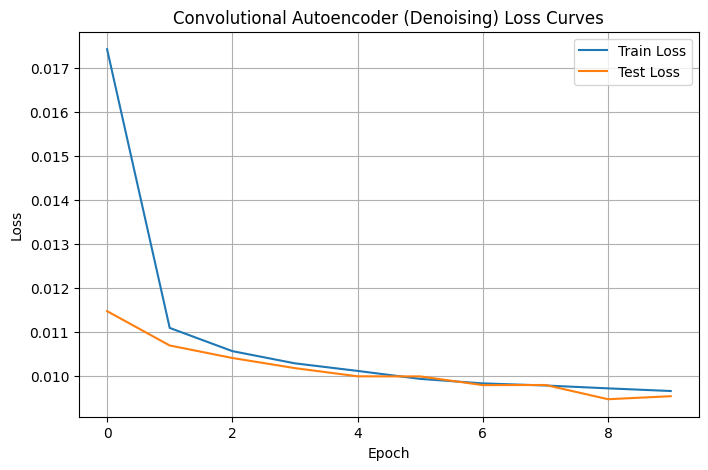

In [40]:
# ===================== YOUR CODE HERE ======================

# ===========================================================
CAE_DENOISE_Trainer.plot_results() # get lost raise not implemented err

<hr>

### <h1 style="text-align: left;">Visualize Results | <span style="color: #9370DB;">CAE</span></h1>

<hr>

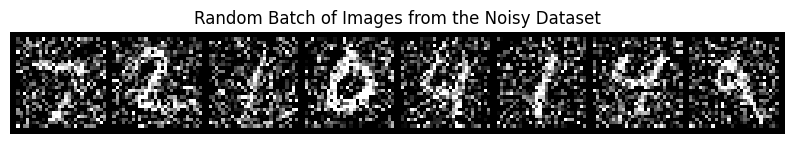

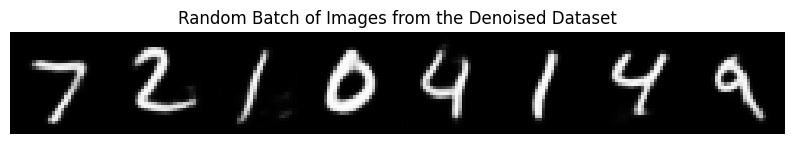

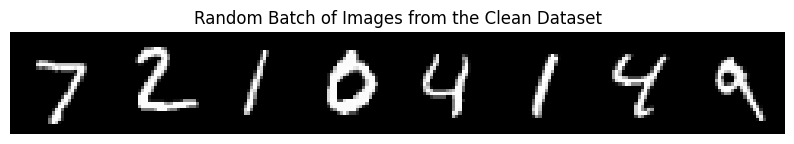

In [41]:
# ===================== YOUR CODE HERE ======================
CAE_DENOISE_Trainer.visualize_denoising(num_images=8)

train_last = CAE_DENOISE_Trainer.train_losses[-1]
test_last = CAE_DENOISE_Trainer.test_losses[-1]
train_min = float(np.min(CAE_DENOISE_Trainer.train_losses))
test_min = float(np.min(CAE_DENOISE_Trainer.test_losses))
Overall_Results["Task 4"] = {
    "Train Loss (Last Epoch)": float(train_last),
    "Test Loss (Last Epoch)": float(test_last),
    "Train Loss (Minimum)": float(train_min),
    "Test Loss (Minimum)": float(test_min),}
# ===========================================================
#raise NotImplementedError
# Update Overall_Results dictionary with actual values after training and evaluation
# Overall_Results["Task 4"] = {
#     "Train Loss (Last Epoch)": None,
#     "Test Loss (Last Epoch)": None,
#     "Train Loss (Minimum)": None,
#     "Test Loss (Minimum)": None,
# }

<hr>

### <h1 style="text-align: left;">Task 4 | <span style="color: #9370DB;">End</span></h1>

<hr>

<hr>

## <h1 style="text-align: left;"><b>Task 5: Image Classification (Reconstruction) | <span style="color: #9370DB;">CIFAR</span></b></h1>

<hr>

### <h2>1. CIFAR-10 Data Preparation:</h2>

<ul>
    <li><b>Original Data:</b> Use the original CIFAR-10 dataset.</li>
    <li><b>LAE Recon Data:</b> Feed the CIFAR-10 images through the LAE model to obtain the reconstructed images.</li>
    <li><b>CAE Recon Data:</b> Feed the CIFAR-10 images through the CAE model to obtain the reconstructed images.</li>
</ul>

<hr>

<h2>2. Classification Model:</h2>

<p>The task requires training a classifier on the following datasets:</p>
<ul>
    <li><b>Original CIFAR-10:</b> Directly train a classifier on the original CIFAR-10 dataset.</li>
</ul>

<hr>

<h2>3. Evaluation Metrics:</h2>

<p>The following metrics should be used to evaluate and compare the performance of the classifier on each test dataset:</p>

<ul>
    <li><b>Accuracy:</b> Percentage of correct classifications.</li>
    <li><b>Precision:</b> The proportion of positive identifications that were actually correct.</li>
    <li><b>Recall:</b> The proportion of actual positives that were correctly identified.</li>
    <li><b>F1-Score:</b> The harmonic mean of precision and recall, providing a balance between them.</li>
</ul>

<hr>

<h2>4. Comparison:</h2>

<p>For comparison:</p>

<ul>
    <li><b>Accuracy Comparison:</b> Compare the classification accuracy for the original data, LAE recon, and CAE recon.</li>
    <li><b>Confusion Matrices:</b> Plot confusion matrices for each classifier to visualize how the model performs across the different classes.</li>
</ul>

<hr>

<h2>5. Analysis:</h2>

<ul>
    <li><b>Feature Retention:</b> Analyze how well the LAE and CAE models preserve features of the original data during reconstruction.</li>
    <li><b>Impact of Reconstruction:</b> Determine the impact of reconstruction on classification accuracy and model performance.</li>
    <li><b>Best Reconstruction Model:</b> Conclude which reconstruction model (LAE or CAE) preserves the original data's classification features better.</li>
</ul>

<hr>

<h2>6. Visualization:</h2>

<ul>
    <li><b>Plot Metrics:</b> Plot the evaluation metrics (accuracy, precision, recall, F1-score) for each dataset to visualize performance differences.</li>
</ul>

In [42]:
# ================== Create Datasets ==================
LAERecon_dataloader =LAE_RECON_Trainer.create_dataset()
CAERecon_dataloader = CAE_RECON_Trainer.create_dataset()

<hr>

### <h1 style="text-align: left;"> Class | <span style="color: #9370DB;">Convolutional Neural Network Recon</span></h1>

<hr>

In [43]:
class CNNRecon(nn.Module):
    def __init__(self):
        super(CNNRecon, self).__init__()
        # ===================== YOUR CODE HERE ======================
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  #c1
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2))
            # nn.ReLU(),
            # nn.MaxPool2d(2, 2),
            # nn.Conv2d(32, 64, 3, padding=1),
            # nn.ReLU(),
            # nn.MaxPool2d(2, 2)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),  #drop
            nn.Linear(256, 10))
        # ===========================================================
       # raise NotImplementedError

    def forward(self, x):
        # ===================== YOUR CODE HERE ======================
        x = self.features(x)
        x = self.classifier(x)  #head
        return x
        # ===========================================================
     #   raise NotImplementedError

<hr>

### <h1 style="text-align: left;"> Class | <span style="color: #9370DB;">CNN Classifier Recon</span></h1>

<hr>

In [44]:
class CNNClassifierRecon:
    def __init__(self, model, train_loader, test_loader, LAERecon_loader, CAERecon_loader, lr=0.001, num_epochs=20, device=None):
        """
        Initializes the CNN classifier for original and reconstructed datasets.

        Args:
            model (nn.Module): The CNN model.
            train_loader (DataLoader): Training dataset loader.
            test_loader (DataLoader): Test dataset loader.
            LAERecon_loader (DataLoader): DataLoader for LAE reconstructed images.
            CAERecon_loader (DataLoader): DataLoader for CAE reconstructed images.
            lr (float): Learning rate.
            num_epochs (int): Number of training epochs.
            device (str or None): 'cuda' or 'cpu', auto-detect if None.
        """
        self.name = "CNN Classifier Reconstruction"
        # ===================== YOUR CODE HERE ======================
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.LAERecon_loader = LAERecon_loader  #lae
        self.CAERecon_loader = CAERecon_loader
        self.lr = lr
        self.num_epochs = num_epochs
        self.device = device if device is not None else torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model.to(self.device)
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)
        self.train_losses = []
        self.train_accuracies = []  #acc
        # ===========================================================
        #raise NotImplementedError

    def train(self):
        """
        Trains the CNN classifier for a specified number of epochs.
        """
        # ===================== YOUR CODE HERE ======================
        for epoch in range(self.num_epochs):
            self.model.train()
            running_loss = 0.0
            correct = 0
            total = 0  #count
            for images, labels in self.train_loader:
                images = images.to(self.device)
                labels = labels.to(self.device)
                self.optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
            epoch_loss = running_loss /len( self.train_loader.dataset)
            epoch_acc = correct/total
            self.train_losses.append(epoch_loss)
            self.train_accuracies.append(epoch_acc)

            print(f"Epoch [{epoch+1}/{self.num_epochs}] Train Loss: {epoch_loss:.6f} Train acc: {epoch_acc:.4f}")
        # ===========================================================
        #raise NotImplementedError

    def evaluate(self, dataloader, print_results=True, epoch=None):
        """
        Evaluates the CNN model on a given dataset.

        Args:
            dataloader (DataLoader): The dataset loader to evaluate on.
            print_results (bool): Whether to print evaluation metrics.
            epoch (int or None): Current epoch number if evaluating during training.

        Returns:
            dict: Contains loss, accuracy, precision, recall, f1-score, and confusion matrix.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        running_loss = 0.0
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for images, labels in dataloader:
                images = images.to(self.device)
                labels = labels.to(self.device)
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                running_loss += loss.item() * images.size(0)
                preds = torch.argmax(outputs, dim=1)
                all_preds.append(preds.cpu())
                all_labels.append(labels.cpu())
        all_preds = torch.cat(all_preds)
        all_labels = torch.cat(all_labels)

        acc = (all_preds == all_labels).float().mean().item()
        cm = confusion_matrix(all_labels.numpy(), all_preds.numpy())

        precisions = []
        recalls = []
        f1s = []
        for c in range(10):
            tp = cm[c, c]
            fp = cm[:, c].sum() - tp
            fn = cm[c, :].sum() - tp
            precision_c = tp / (tp+fp +1e-12)
            recall_c = tp / (tp + fn+1e-12)
            f1_c = 2 * precision_c *recall_c/(precision_c + recall_c +1e-12)
            precisions.append(precision_c)
            recalls.append(recall_c)
            f1s.append(f1_c)

        precision = float(np.mean(precisions))
        recall = float(np.mean(recalls))
        f1 = float(np.mean(f1s))
        avg_loss = running_loss/len(dataloader.dataset)
        results = {
            "loss": float(avg_loss),
            "accuracy": float(acc),  #acc
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "confusion_matrix": cm}
        if print_results:
            tag = "" if epoch is None else f" (Epoch {epoch})"
            print(f"Eval{tag} Loss: {avg_loss:.6f} Acc: {acc:.4f} Prec: {precision:.4f} Rec: {recall:.4f} F1: {f1:.4f}")

        return results
        # ===========================================================
        #raise NotImplementedError

    def save_model(self, path="CNN_RECON.pth"):
        """
        Saves the trained model to the specified file path.

        Args:
            path (str): File path to save the model.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to {path}")

    def load_model(self, path="CNN_RECON.pth"):
        """
        Loads the trained model from the specified file path.

        Args:
            path (str): File path of the saved model.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from {path}")

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">CNN Classifier Recon</span></h1>

<hr>

In [45]:
CNN_RECON_Model =CNNRecon()
CNN_CLASSIFIER_RECON_Trainer = CNNClassifierRecon(CNN_RECON_Model,CIFAR_10_trainloader,CIFAR_10_testloader, LAERecon_dataloader,  CAERecon_dataloader, lr=LEARNING_RATE, num_epochs=EPOCHS, device=None )

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">CNN Classifier Recon</span></h1>

<hr>

In [46]:
# ===================== YOUR CODE HERE ======================
CNN_CLASSIFIER_RECON_Trainer.train()
# ===========================================================
#raise NotImplementedError

Epoch [1/10] Train Loss: 1.652845 Train acc: 0.3929
Epoch [2/10] Train Loss: 1.278787 Train acc: 0.5388
Epoch [3/10] Train Loss: 1.097361 Train acc: 0.6108
Epoch [4/10] Train Loss: 0.979695 Train acc: 0.6542
Epoch [5/10] Train Loss: 0.895787 Train acc: 0.6870
Epoch [6/10] Train Loss: 0.817056 Train acc: 0.7113
Epoch [7/10] Train Loss: 0.769905 Train acc: 0.7292
Epoch [8/10] Train Loss: 0.712340 Train acc: 0.7499
Epoch [9/10] Train Loss: 0.667803 Train acc: 0.7646
Epoch [10/10] Train Loss: 0.617846 Train acc: 0.7809


<hr>

### <h1 style="text-align: left;">Results | <span style="color: #9370DB;">CNN Classifier Recon</span></h1>

<hr>

In [47]:
# ===================== YOUR CODE HERE ======================
train_last_loss = CNN_CLASSIFIER_RECON_Trainer.train_losses[-1]
train_min_loss = float(np.min(CNN_CLASSIFIER_RECON_Trainer.train_losses))  #min
train_last_acc = CNN_CLASSIFIER_RECON_Trainer.train_accuracies[-1]
train_max_acc = float(np.max(CNN_CLASSIFIER_RECON_Trainer.train_accuracies))
orig_res = CNN_CLASSIFIER_RECON_Trainer.evaluate(CIFAR_10_testloader, print_results=True)
lae_res = CNN_CLASSIFIER_RECON_Trainer.evaluate(LAERecon_dataloader, print_results=True)
cae_res = CNN_CLASSIFIER_RECON_Trainer.evaluate(CAERecon_dataloader, print_results=True)  #cae

Overall_Results["Task 5"] = {
    "Train Loss (Last Epoch)": float(train_last_loss),
    "Train Accuracy (Last Epoch)": float(train_last_acc),
    "Train Loss (Minimum)": float(train_min_loss),
    "Train Accuracy (Maximum)": float(train_max_acc),
    "Test Loss (Original Dataset)": float(orig_res["loss"]),
    "Test Accuracy (Original Dataset)": float(orig_res["accuracy"]),
    "Test Precision (Original Dataset)": float(orig_res["precision"]),
    "Test Recall (Original Dataset)": float(orig_res["recall"]),
    "Test F1 Score (Original Dataset)": float(orig_res["f1"]),

    "Test Loss (LAERecon Dataset)": float(lae_res["loss"]),
    "Test Accuracy (LAERecon Dataset)": float(lae_res["accuracy"]),
    "Test Precision (LAERecon Dataset)": float(lae_res["precision"]),
    "Test Recall (LAERecon Dataset)": float(lae_res["recall"]),
    "Test F1 Score (LAERecon Dataset)": float(lae_res["f1"]),

    "Test Loss (CAERecon Dataset)": float(cae_res["loss"]),
    "Test Accuracy (CAERecon Dataset)": float(cae_res["accuracy"]),
    "Test Precision (CAERecon Dataset)": float(cae_res["precision"]),
    "Test Recall (CAERecon Dataset)": float(cae_res["recall"]),
    "Test F1 Score (CAERecon Dataset)": float(cae_res["f1"]),
}
# ===========================================================#
#
#raise NotImplementedError
# Update Overall_Results dictionary with actual values after training and evaluation
# Overall_Results["Task 5"] = {
#     "Train Loss (Last Epoch)": None,
#     "Test Loss (Last Epoch)": None,
#     "Train Accuracy (Last Epoch)": None,
#     "Test Accuracy (Last Epoch)": None,
#     "Train Loss (Minimum)": None,
#     "Test Loss (Minimum)": None,
#     "Train Accuracy (Maximum)": None,
#     "Test Accuracy (Maximum)": None,
# }

Eval Loss: 0.758107 Acc: 0.7408 Prec: 0.7440 Rec: 0.7408 F1: 0.7411
Eval Loss: 2.998432 Acc: 0.2830 Prec: 0.4907 Rec: 0.2830 F1: 0.2231
Eval Loss: 1.543725 Acc: 0.4990 Prec: 0.6136 Rec: 0.4990 F1: 0.5029


<hr>

### <h1 style="text-align: left;">Analysis | <span style="color: #9370DB;">CNN Classifier Recon</span></h1>

<hr>

**Answer here:**
the cnn trained on original cifar-10 generalizes reasonably to the original test set (Acc ~= 0.7408, F1 ~= 0.7411), showing that the clasifier learned useful features from clean images.when we evaluate on reconstructed images, performance drops signiicantly, especially for LAERecon (Acc ~= 0.2830, F1 ~=0.2231). This suggests that the linear autoencoder destroys or blurs discriminative details such as textures, edges, and color cues that the classifier relies on

CAERecon performs better (Acc ~= 0.4990, F1 ~= 0.5029), which matches the theory that convolutional autoencoders preserve spatial structure better than purely linear compression.however, the large gap compared to the original performance still implies that the reconstructions lose class specific information

Overall, reconstruction reduces feature retention. CAERecon preserves classification relevant features better than LAERecon, but neither method fully preserves them.m
<hr>

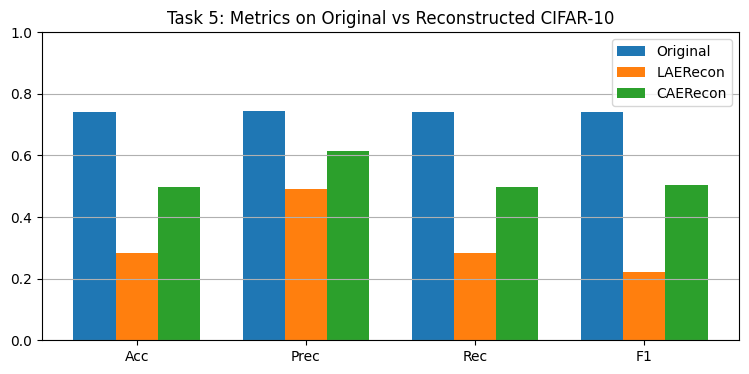

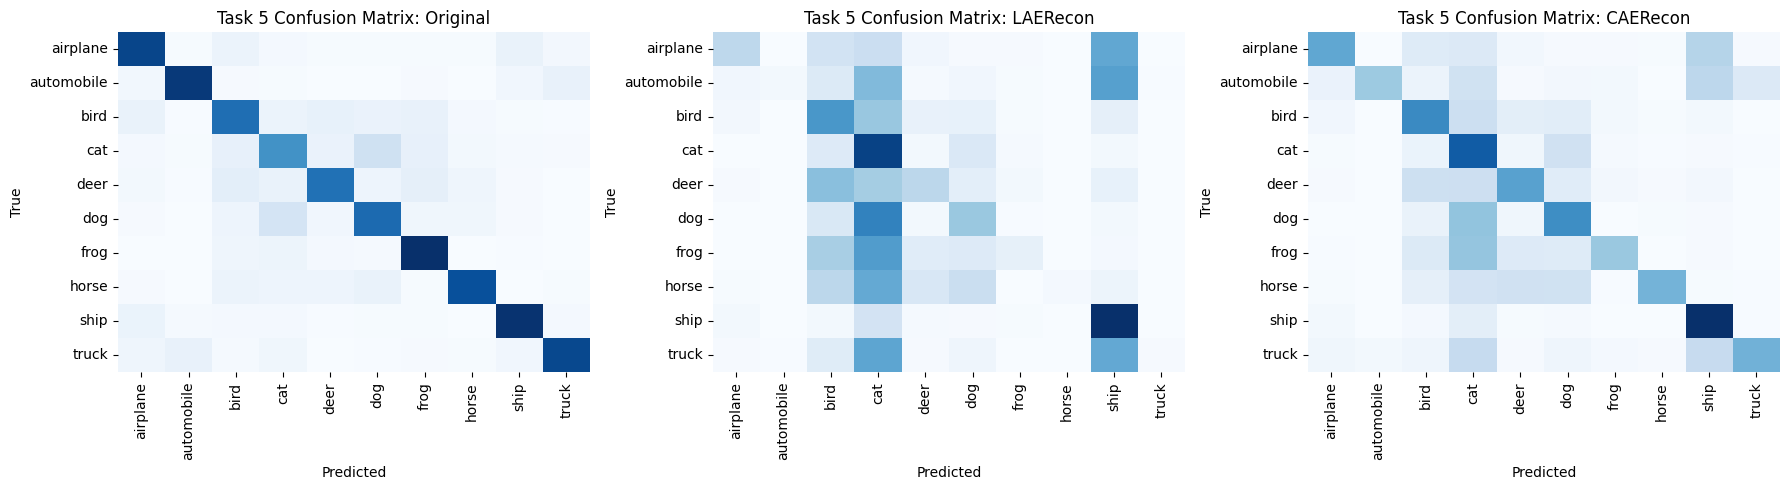

In [48]:
#since they also mentioned plots: -- CONSIDER THIS CELL OPTIONAL. I WAS JUST SAFE AND ADDED THIS BECAUSE YOUR DESCRIPTION MENTIONED "PLOTTING"
# use aid from ai because i domt know syntax for plotting offc
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score  #metrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  #heatmap

def eval_metrics_cm(model, dataloader, device, num_classes):  #helper
    model.eval()
    ce = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)  #ondevice
            y = y.to(device)
            logits = model(x)
            total_loss += ce(logits, y).item()
            preds = logits.argmax(dim=1)
            all_preds.append(preds.cpu())
            all_targets.append(y.cpu())
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    avg_loss = total_loss / len(all_targets)
    acc = accuracy_score(all_targets, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average="weighted", zero_division=0)  #weighted
    cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_classes)))
    return {"loss": avg_loss, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm}

device = CNN_CLASSIFIER_RECON_Trainer.device if hasattr(CNN_CLASSIFIER_RECON_Trainer, "device") else next(CNN_RECON_Model.parameters()).device
cifar_classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]  #labels

res_orig = eval_metrics_cm(CNN_CLASSIFIER_RECON_Trainer.model, CIFAR_10_testloader, device, 10)
res_lae= eval_metrics_cm(CNN_CLASSIFIER_RECON_Trainer.model, LAERecon_dataloader, device, 10)  #lae
res_cae = eval_metrics_cm(CNN_CLASSIFIER_RECON_Trainer.model, CAERecon_dataloader, device, 10)

names = ["Original", "LAERecon", "CAERecon"]
pack = [res_orig, res_lae, res_cae]

metrics = ["accuracy", "precision", "recall", "f1"]
vals = np.array([[p[m] for m in metrics] for p in pack])

plt.figure(figsize=(9, 4))
x = np.arange(len(metrics))
w = 0.25
plt.bar(x - w, vals[0], w, label=names[0])
plt.bar(x,vals[1], w, label=names[1])  #bars
plt.bar(x + w, vals[2], w, label=names[2])
plt.xticks(x, ["Acc", "Prec", "Rec", "F1"])
plt.ylim(0, 1.0)
plt.title("Task 5: Metrics on Original vs Reconstructed CIFAR-10")  #metricbar
plt.legend()
plt.grid(True, axis="y")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, title, p in zip(axes, names, pack):
    sns.heatmap(p["cm"], ax=ax, cmap="Blues", cbar=False, xticklabels=cifar_classes, yticklabels=cifar_classes)
    ax.set_title(f"Task 5 Confusion Matrix: {title}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

<hr>

### <h1 style="text-align: left;">Task 5 | <span style="color: #9370DB;">End</span></h1>

<hr>

<hr>

## <h1 style="text-align: left;"><b>Task 6: Image Classification (Denoising) | <span style="color: #9370DB;">MNIST</span></b></h1>

<hr>

### <h2>1. MNIST Data Preparation:</h2>

<ul>
    <li><b>Original Data:</b> Use the original MNIST dataset.</li>
    <li><b>LAE Denoised Data:</b> Pass the noisy MNIST images through the LAE model to obtain the denoised images.</li>
    <li><b>CAE Denoised Data:</b> Pass the noisy MNIST images through the CAE model to obtain the denoised images.</li>
</ul>

<hr>

<h2>2. Classification Model:</h2>

<p>The task requires training a classifier on the following datasets:</p>
<ul>
    <li><b>Original MNIST:</b> Train a classifier on the original MNIST dataset.</li>
</ul>

<hr>

<h2>3. Evaluation Metrics:</h2>

<p>The following metrics should be used to evaluate and compare the performance of the classifier on each test dataset:</p>

<ul>
    <li><b>Accuracy:</b> Percentage of correct classifications.</li>
    <li><b>Precision:</b> The proportion of positive identifications that were actually correct.</li>
    <li><b>Recall:</b> The proportion of actual positives that were correctly identified.</li>
    <li><b>F1-Score:</b> The harmonic mean of precision and recall, providing a balance between them.</li>
</ul>

<hr>

<h2>4. Comparison:</h2>

<p>For comparison:</p>

<ul>
    <li><b>Accuracy Comparison:</b> Compare the classification accuracy for the original data, LAE denoised, and CAE denoised images.</li>
    <li><b>Confusion Matrices:</b> Plot confusion matrices for each classifier to visualize how the model performs across different classes.</li>
</ul>

<hr>

<h2>5. Analysis:</h2>

<ul>
    <li><b>Noise Reduction Effectiveness:</b> Analyze how well the LAE and CAE models remove noise while retaining key features.</li>
    <li><b>Impact of Denoising:</b> Determine the impact of denoising on classification accuracy and model performance.</li>
    <li><b>Best Denoising Model:</b> Conclude which denoising model (LAE or CAE) preserves the original data's classification features better.</li>
</ul>

<hr>

<h2>6. Visualization:</h2>

<ul>
    <li><b>Plot Metrics:</b> Plot the evaluation metrics (accuracy, precision, recall, F1-score) for each dataset to visualize performance differences.</li>
</ul>


In [49]:
# ================== Create Datasets ==================
LAEDenoise_dataloader =LAE_DENOISE_Trainer.create_dataset()
CAEDenoise_dataloader = CAE_DENOISE_Trainer.create_dataset()

<hr>

### <h1 style="text-align: left;"> Class | <span style="color: #9370DB;">Convolutional Neural Network Denoising</span></h1>

<hr>

In [50]:
class CNNDenoise(nn.Module):
    def __init__(self):
        super(CNNDenoise, self).__init__()
        # ===================== YOUR CODE HERE ======================
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  #14
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10) )
        # ===========================================================
     #   raise NotImplementedError

    def forward(self, x):
        # ===================== YOUR CODE HERE ======================
        x = self.features(x)
        x = self.classifier(x)
        return x
        # ===========================================================
       # raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">CNN Classifier Denoising</span></h1>

<hr>

In [51]:
class CNNClassifierDenoise:
    def __init__(self, model, train_loader, test_loader, LAEDenoise_loader, CAEDenoise_loader, lr=0.001, num_epochs=20, device=None):
        """
        Initializes the CNN classifier for original and denoised datasets.

        Args:
            model (nn.Module): The CNN model.
            train_loader (DataLoader): Training dataset loader.
            test_loader (DataLoader): Test dataset loader.
            LAEDenoise_loader (DataLoader): DataLoader for LAE denoised images.
            CAEDenoise_loader (DataLoader): DataLoader for CAE denoised images.
            lr (float): Learning rate.
            num_epochs (int): Number of training epochs.
            device (str or None): 'cuda' or 'cpu', auto-detect if None.
        """
        self.name = "CNN Classifier Denoising"
        # ===================== YOUR CODE HERE ======================
        self.model = model
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.LAEDenoise_loader = LAEDenoise_loader
        self.CAEDenoise_loader = CAEDenoise_loader  #cae
        self.lr = lr
        self.num_epochs = num_epochs
        self.device = device if device is not None else torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model.to(self.device)
        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=self.lr)
        self.train_losses = []
        self.train_accuracies = []
        # ===========================================================
      #  raise NotImplementedError

    def train(self):
        """
        Trains the CNN classifier for a specified number of epochs.
        """
        # ===================== YOUR CODE HERE ======================
        for epoch in range(self.num_epochs):
            self.model.train()
            running_loss = 0.0
            correct = 0
            total = 0
            for images, labels in self.train_loader:
                images = images.to(self.device)
                labels = labels.to(self.device)  #y
                self.optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * images.size(0)
                preds = torch.argmax(outputs, dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
            epoch_loss = running_loss / len(self.train_loader.dataset)
            epoch_acc = correct / total
            self.train_losses.append(epoch_loss)
            self.train_accuracies.append(epoch_acc)
            print(f"Epoch [{epoch+1}/{self.num_epochs}] Train Loss: {epoch_loss:.6f} Train Acc: {epoch_acc:.4f}")
        # ===========================================================
      #  raise NotImplementedError

    def evaluate(self, dataloader, print_results=True, epoch=None):
        """
        Evaluates the CNN model on a given dataset.

        Args:
            dataloader (DataLoader): The dataset loader to evaluate on.
            print_results (bool): Whether to print evaluation metrics.
            epoch (int or None): Current epoch number if evaluating during training.

        Returns:
            dict: Contains loss, accuracy, precision, recall, f1-score, and confusion matrix.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        running_loss = 0.0
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for images, labels in dataloader:
                images = images.to(self.device)
                labels = labels.to(self.device)
                outputs = self.model(images)
                loss = self.criterion(outputs,labels)
                running_loss += loss.item() *images.size(0)
                preds = torch.argmax(outputs, dim=1)
                all_preds.append(preds.cpu())
                all_labels.append(labels.cpu())

        all_preds = torch.cat(all_preds)
        all_labels = torch.cat(all_labels)
        acc = (all_preds == all_labels).float().mean().item()  #acc
        cm = confusion_matrix(all_labels.numpy(), all_preds.numpy())
        precisions = []
        recalls = []
        f1s = []
        for c in range(10):
            tp = cm[c, c]
            fp = cm[:, c].sum() - tp
            fn = cm[c, :].sum() - tp
            precision_c = tp / (tp+fp+1e-12)
            recall_c = tp /(tp+ fn+1e-12)
            f1_c = 2 * precision_c*recall_c /(precision_c + recall_c +1e-12)
            precisions.append(precision_c)
            recalls.append(recall_c)
            f1s.append(f1_c)

        precision = float(np.mean(precisions))
        recall = float(np.mean(recalls))
        f1 = float(np.mean(f1s))
        avg_loss = running_loss / len(dataloader.dataset)
        results = {
            "loss": float(avg_loss),
            "accuracy": float(acc),
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "confusion_matrix": cm}

        if print_results:
            tag = "" if epoch is None else f" (Epoch {epoch})"
            print(f"Eval{tag} Loss: {avg_loss:.6f} Acc: {acc:.4f} Prec: {precision:.4f} Rec: {recall:.4f} F1: {f1:.4f}")

        return results
        # ===========================================================
        #raise NotImplementedError

    def save_model(self, path="CNN_Denoise.pth"):
        """
        Saves the trained model to the specified file path.

        Args:
            path (str): File path to save the model.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to {path}")

    def load_model(self, path="CNN_Denoise.pth"):
        """
        Loads the trained model from the specified file path.

        Args:
            path (str): File path of the saved model.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from {path}")

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">CNN Classifier Denoising</span></h1>

<hr>

In [52]:
CNN_DENOISE_Model =CNNDenoise()
CNN_CLASSIFIER_DENOISE_Trainer = CNN_CLASSIFIER_DENOISE_Trainer = CNNClassifierDenoise(CNN_DENOISE_Model,MNIST_trainloader,MNIST_testloader, LAEDenoise_dataloader,CAEDenoise_dataloader,  lr=LEARNING_RATE,num_epochs=EPOCHS, device=None )

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">CNN Classifier Denoising</span></h1>

<hr>

In [53]:
# ===================== YOUR CODE HERE ======================
CNN_CLASSIFIER_DENOISE_Trainer.train()
# ===========================================================
#raise NotImplementedError

Epoch [1/10] Train Loss: 0.372195 Train Acc: 0.8824
Epoch [2/10] Train Loss: 0.092786 Train Acc: 0.9721
Epoch [3/10] Train Loss: 0.067128 Train Acc: 0.9790
Epoch [4/10] Train Loss: 0.054174 Train Acc: 0.9828
Epoch [5/10] Train Loss: 0.043052 Train Acc: 0.9868
Epoch [6/10] Train Loss: 0.036343 Train Acc: 0.9882
Epoch [7/10] Train Loss: 0.032009 Train Acc: 0.9896
Epoch [8/10] Train Loss: 0.029174 Train Acc: 0.9906
Epoch [9/10] Train Loss: 0.022482 Train Acc: 0.9926
Epoch [10/10] Train Loss: 0.021475 Train Acc: 0.9931


<hr>

### <h1 style="text-align: left;">Results | <span style="color: #9370DB;">CNN Classifier Denoising</span></h1>

<hr>

In [54]:
# ===================== YOUR CODE HERE ======================
train_last_loss = CNN_CLASSIFIER_DENOISE_Trainer.train_losses[-1]
train_min_loss = float(np.min(CNN_CLASSIFIER_DENOISE_Trainer.train_losses))
train_last_acc = CNN_CLASSIFIER_DENOISE_Trainer.train_accuracies[-1]  #last
train_max_acc = float(np.max(CNN_CLASSIFIER_DENOISE_Trainer.train_accuracies))
orig_res = CNN_CLASSIFIER_DENOISE_Trainer.evaluate(MNIST_testloader, print_results=True)
lae_res = CNN_CLASSIFIER_DENOISE_Trainer.evaluate(LAEDenoise_dataloader, print_results=True)
cae_res = CNN_CLASSIFIER_DENOISE_Trainer.evaluate(CAEDenoise_dataloader, print_results=True)
Overall_Results["Task 6"] = {
    "Train Loss (Last Epoch)": float(train_last_loss),
    "Train Accuracy (Last Epoch)": float(train_last_acc),
    "Train Loss (Minimum)": float(train_min_loss),
    "Train Accuracy (Maximum)": float(train_max_acc),
    "Test Loss (Original Dataset)": float(orig_res["loss"]),
    "Test Accuracy (Original Dataset)": float(orig_res["accuracy"]),
    "Test Precision (Original Dataset)": float(orig_res["precision"]),
    "Test Recall (Original Dataset)": float(orig_res["recall"]),
    "Test F1 Score (Original Dataset)": float(orig_res["f1"]),
    "Test Loss (LAEDenoise Dataset)": float(lae_res["loss"]),
    "Test Accuracy (LAEDenoise Dataset)": float(lae_res["accuracy"]),
    "Test Precision (LAEDenoise Dataset)": float(lae_res["precision"]),
    "Test Recall (LAEDenoise Dataset)": float(lae_res["recall"]),
    "Test F1 Score (LAEDenoise Dataset)": float(lae_res["f1"]),
    "Test Loss (CAEDenoise Dataset)": float(cae_res["loss"]),
    "Test Accuracy (CAEDenoise Dataset)": float(cae_res["accuracy"]),
    "Test Precision (CAEDenoise Dataset)": float(cae_res["precision"]),
    "Test Recall (CAEDenoise Dataset)": float(cae_res["recall"]),
    "Test F1 Score (CAEDenoise Dataset)": float(cae_res["f1"]),
}
# ===========================================================
#aise NotImplementedError
# Update Overall_Results dictionary with actual values after training and evaluation
# Overall_Results["Task 6"] = {
#     "Train Loss (Last Epoch)": None,
#     "Test Loss (Last Epoch)": None,
#     "Train Accuracy (Last Epoch)": None,
#     "Test Accuracy (Last Epoch)": None,
#     "Train Loss (Minimum)": None,
#     "Test Loss (Minimum)": None,
#     "Train Accuracy (Maximum)": None,
#     "Test Accuracy (Maximum)": None,
# }

Eval Loss: 0.027589 Acc: 0.9917 Prec: 0.9918 Rec: 0.9916 F1: 0.9917
Eval Loss: 0.302909 Acc: 0.9264 Prec: 0.9283 Rec: 0.9246 F1: 0.9255
Eval Loss: 0.098769 Acc: 0.9746 Prec: 0.9749 Rec: 0.9741 F1: 0.9744


<hr>

### <h1 style="text-align: left;">Analysis | <span style="color: #9370DB;">CNN Classifier Denoising</span></h1>

<hr>

**Answer here:**
cNN trained on clean/original MNIST performs extremely well on the original test set (Acc ~= 0.9917, F1 ~= 0.9917), which shows that it learned strong digit discriminative features under the clean data distribution.when I evaluate on denoised outputs, performance depends entirely on whether the denoiser removes noise without deleting digit structure such as strokes, edges, and thickness

LAE Denoise retains most of those key features. It's denoised test performance drops but remains strong (Acc ~= 0.9264, F1 ~= 0.9255), which suggests that it successfuly reduce noise while keeping the shapes readable.This matches what I expect when a denoiser smooths noise but preserves global digit silhouettes.

CAE Denoise preservs classification features better then LAE denoise in this run, because its accuracy and f1 are much closer to the clean baseline(Acc ~= 0.9746, F1 ~= 0.9744), showing stronger noise removal with minimal loss of discriminative structure

Overall, both denoisers help retain digit structure, but CAE Denoise is best in my run (Acc ≈ 0.9746, F1 ≈ 0.9744) because it stays closest to the clean-data performance, indicating stronger noise removal with minimal loss of discriminative stroke information
<hr>

<hr>

### <h1 style="text-align: left;">Task 6 | <span style="color: #9370DB;">End</span></h1>

<hr>

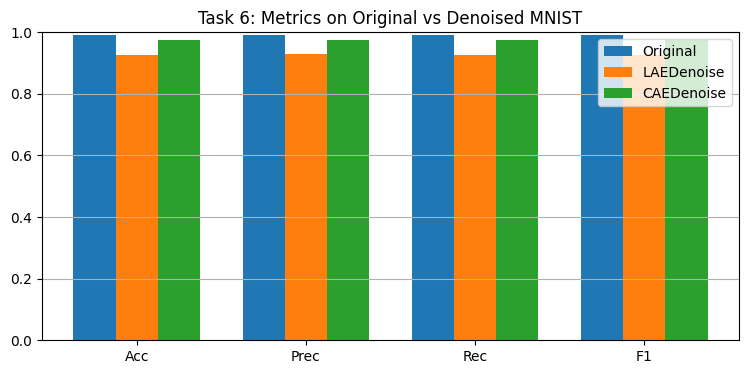

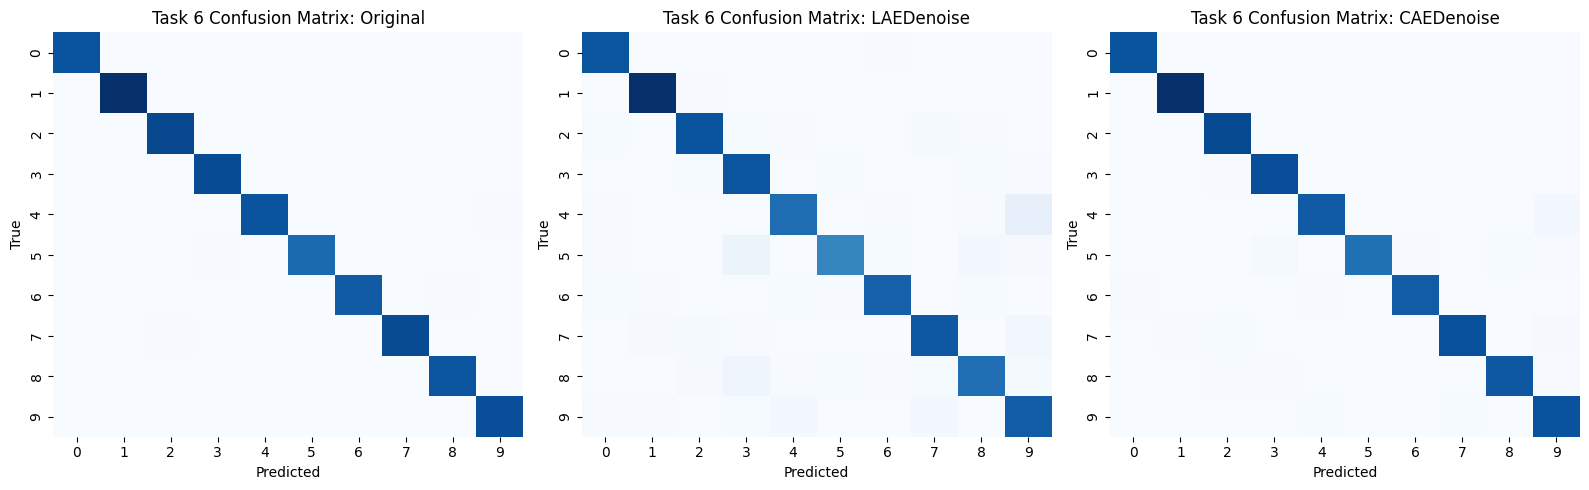

In [55]:
# for task 6, same as for task 5 since yall asked for plots
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  #viz

def eval_metrics_cm(model, dataloader, device, num_classes):
    model.eval()
    ce = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            y = y.to(device)  #labels
            logits = model(x)
            total_loss += ce(logits, y).item()
            preds = logits.argmax(dim=1)
            all_preds.append(preds.cpu())
            all_targets.append(y.cpu())
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    avg_loss = total_loss / len(all_targets)
    acc = accuracy_score(all_targets, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average="weighted", zero_division=0)
    cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_classes)))  #cm
    return {"loss": avg_loss, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm}

device = CNN_CLASSIFIER_DENOISE_Trainer.device if hasattr(CNN_CLASSIFIER_DENOISE_Trainer, "device") else next(CNN_DENOISE_Model.parameters()).device
mnist_classes = [str(i) for i in range(10)]

res_orig = eval_metrics_cm(CNN_CLASSIFIER_DENOISE_Trainer.model, MNIST_testloader, device, 10)
res_lae  = eval_metrics_cm(CNN_CLASSIFIER_DENOISE_Trainer.model, LAEDenoise_dataloader, device, 10)
res_cae  = eval_metrics_cm(CNN_CLASSIFIER_DENOISE_Trainer.model, CAEDenoise_dataloader, device, 10)  #cae

names = ["Original", "LAEDenoise", "CAEDenoise"]
pack = [res_orig, res_lae, res_cae]

metrics = ["accuracy", "precision", "recall", "f1"]
vals = np.array([[p[m] for m in metrics] for p in pack])

plt.figure(figsize=(9, 4))
x = np.arange(len(metrics))
w = 0.25
plt.bar(x - w, vals[0], w, label=names[0])
plt.bar(x,vals[1], w, label=names[1])
plt.bar(x +w, vals[2], w, label=names[2])
plt.xticks(x, ["Acc", "Prec", "Rec", "F1"])
plt.ylim(0, 1.0)
plt.title("Task 6: Metrics on Original vs Denoised MNIST")  #metricbar
plt.legend()
plt.grid(True, axis="y")
plt.show()

fig, axes= plt.subplots(1, 3, figsize=(16, 5))
for ax, title, p in zip(axes, names, pack):
    sns.heatmap(p["cm"], ax=ax, cmap="Blues", cbar=False, xticklabels=mnist_classes, yticklabels=mnist_classes)
    ax.set_title(f"Task 6 Confusion Matrix: {title}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

<hr>

## <h1 style="text-align: left;"><b>Task 7: Classification using Latent Space | <span style="color: #9370DB;">CIFAR-10</span></b></h1>

<hr>

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">Convolutional AutoEncoder</span></h1>

<hr>

In [56]:
class ConvolutionalAutoencoderLatentSpace(nn.Module):
    def __init__(self):
        super(ConvolutionalAutoencoderLatentSpace, self).__init__()
        # ===================== YOUR CODE HERE ======================
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2))

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid())  #pix)
        # ===========================================================
      #  raise NotImplementedError

    def forward(self, x):
        # ===================== YOUR CODE HERE ======================
        z = self.encoder(x)  #latent
        x = self.decoder(z)
        return x
        # ===========================================================
       # raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Class | <span style="color: #9370DB;">Trainer + Interpolation</span></h1>

<hr>

### <h2>Interpolation in Latent Space</h2>

<p>Interpolation in an autoencoder's latent space involves generating intermediate representations between two encoded data points.
In the <code>AutoencoderTrainer</code> class, this is implemented through two methods:</p>

<ul>
    <li><b><code>interpolate_same_class</code></b>: Performs interpolation between two samples of the same class.</li>
    <li><b><code>interpolate_different_classes</code></b>: Interpolates between two samples belonging to different classes.</li>
</ul>

<hr>

<h2>Why Do We Perform Interpolation?</h2>

<ul>
    <li>
        <b>Understanding the Learned Latent Space</b>
        <ul>
            <li>By interpolating between encoded representations, we can analyze how the model organizes and encodes data.</li>
            <li>A well-trained autoencoder should produce smooth transitions between interpolated samples.</li>
        </ul>
    </li>
    <li>
        <b>Semantic Meaning of Latent Representations</b>
        <ul>
            <li>If interpolation results in meaningful intermediate samples, it suggests that the latent space is structured logically.</li>
            <li>For same-class interpolation, a gradual shift should preserve key features of the class.</li>
            <li>For different-class interpolation, the transition should indicate how the model bridges the gap between distinct classes.</li>
        </ul>
    </li>
    <li>
        <b>Evaluating the Decoder</b>
        <ul>
            <li>The reconstructed interpolated samples help determine whether the decoder can generalize well beyond just memorizing training samples.</li>
        </ul>
    </li>
</ul>

<hr>

<h2>How the <code>AutoencoderTrainer</code> Class Implements Interpolation</h2>

<p>In the provided implementation:</p>

<ul>
    <li>The <b>encoder</b> compresses input images into a latent representation.</li>
    <li>Two latent vectors are selected based on class labels.</li>
    <li>Intermediate points are computed using weighted combinations of the two latent vectors.</li>
    <li>The <b>decoder</b> reconstructs images from the interpolated latent representations.</li>
    <li>The function <code>visualize_interpolation</code> helps in analyzing how interpolation affects the generated samples.</li>
</ul>

<p>By running these interpolation methods, one can visually inspect whether the autoencoder has learned a meaningful latent space.</p>

In [57]:
class AutoencoderTrainer:
    """
    A class to train an autoencoder model and perform latent space interpolations.
    This trainer supports training, latent space interpolations between
    same and different class samples, visualization, and model saving/loading.
    """

    def __init__(self, model, device="cuda" if torch.cuda.is_available() else "cpu"):
        """
        Initializes the AutoencoderTrainer.

        Args:
            model: The autoencoder model to be trained and evaluated.
            device: The device to run computations on ("cuda" or "cpu").
        """
        # ===================== YOUR CODE HERE ======================
        self.model = model
        self.device = device  #dev
        self.model.to(self.device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=0.001)
        # ===========================================================
     #   raise NotImplementedError

    def train(self, train_loader, epochs=10):
        """
        Trains the autoencoder model using mean squared error loss.

        Args:
            train_loader: DataLoader for training dataset.
            epochs: Number of training epochs (default is 10).
        """
        # ===================== YOUR CODE HERE ======================
        self.model.train()
        for epoch in range(epochs):
            running_loss = 0.0

            for images, _ in train_loader:
                images = images.to(self.device)
                self.optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(outputs, images)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item()*images.size(0)  #sum

            avg_loss = running_loss / len(train_loader.dataset)
            print(f"Epoch [{epoch+1}/{epochs}] Loss: {avg_loss:.6f}")
        # ===========================================================
      #  raise NotImplementedError

    def interpolate_same_class(self, dataloader, steps=10):
        """
        Performs latent space interpolation between two images of the same class.

        Args:
            dataloader: DataLoader containing the dataset.
            steps: Number of interpolation steps (default is 10).

        Returns:
            A tensor containing interpolated images if successful, else None.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        images, labels = next(iter(dataloader))
        images = images.to(self.device)
        labels = labels.to(self.device)
        for cls in labels.unique():
            idx = (labels == cls).nonzero(as_tuple=True)[0]
            if idx.numel() >= 2:
                i1, i2 = idx[0].item(), idx[1].item()
                img1 = images[i1:i1+1]
                img2 = images[i2:i2+1]  #img2
                break
        else:
            return None
        with torch.no_grad():
            z1 = self.model.encoder(img1)
            z2 = self.model.encoder(img2)
            alphas = torch.linspace(0, 1, steps, device=self.device)
            interps = []
            for a in alphas:
                z = (1 - a) * z1 + a * z2
                out = self.model.decoder(z)
                interps.append(out.cpu())
        interpolated_images = torch.cat(interps, dim=0)
        return interpolated_images
        # ===========================================================
        #raise NotImplementedError

    def interpolate_different_classes(self, dataloader, steps=10):
        """
        Performs latent space interpolation between two images of different classes.

        Args:
            dataloader: DataLoader containing the dataset.
            steps: Number of interpolation steps (default is 10).

        Returns:
            A tensor containing interpolated images if successful, else None.
        """
        # ===================== YOUR CODE HERE ======================
        self.model.eval()
        images, labels = next(iter(dataloader))
        images = images.to(self.device)
        labels = labels.to(self.device)
        uniq = labels.unique()
        if uniq.numel() < 2:
            return None
        c1 = uniq[0].item()
        c2 = uniq[1].item()  #two
        i1 = (labels == c1).nonzero(as_tuple=True)[0][0].item()
        i2 = (labels == c2).nonzero(as_tuple=True)[0][0].item()
        img1 = images[i1:i1+1]
        img2 = images[i2:i2+1]
            #         idx = (labels == cls).nonzero(as_tuple=True)[0]
            # if idx.numel() >= 2:
            #     i1, i2 = idx[0].item(), idx[1].item()
            #     img1 = images[i1:i1+1]
            #     img2 = images[i2:i2+1]  #img2
            #     break

        with torch.no_grad():
            z1 = self.model.encoder(img1)
            z2 = self.model.encoder(img2)
            alphas = torch.linspace(0, 1, steps, device=self.device)
            interps = []
            for a in alphas:
                z = (1 - a) * z1 + a * z2
                out = self.model.decoder(z)
                interps.append(out.cpu())
        interpolated_images = torch.cat(interps, dim=0)
        return interpolated_images
        # ===========================================================
       # raise NotImplementedError

    def visualize_interpolation(self, img1, img2, interpolated_images, title):
        """
        Visualizes interpolation results between two images.

        Args:
            img1: First image.
            img2: Second image.
            interpolated_images: List of interpolated images.
            title: Title for the visualization.
        """
        # ===================== YOUR CODE HERE ======================
        plt.figure(figsize=(12, 3))
        imgs = [img1.cpu(), *[x for x in interpolated_images], img2.cpu()]  #list
        for i, im in enumerate(imgs):
            plt.subplot(1, len(imgs), i + 1)
            npimg = im.squeeze(0).permute(1, 2, 0).numpy()
            plt.imshow(npimg)
            plt.axis("off")
        plt.suptitle(title)
        plt.show()
        # ===========================================================
     #   raise NotImplementedError

    def save_model(self, path="/models/CAE_LATENT_SPACE.pth"):
        """
        Saves the model state to the specified file.

        Args:
            path: File path where the model will be saved.
        """
        torch.save(self.model.state_dict(), path)
        print(f"Model saved to {path}")

    def load_model(self, path="/models/CAE_LATENT_SPACE.pth"):
        """
        Loads the model state from the specified file.

        Args:
            path: File path from where the model will be loaded.
        """
        self.model.load_state_dict(torch.load(path, map_location=self.device))
        self.model.to(self.device)
        print(f"Model loaded from {path}")

<hr>

### <h1 style="text-align: left;">Model Setup | <span style="color: #9370DB;">CAE Latent Space</span></h1>

<hr>

In [58]:
CAE_LATENT_SPACE_Model = ConvolutionalAutoencoderLatentSpace()
CAE_LATENT_SPACE_Trainer =AutoencoderTrainer(CAE_LATENT_SPACE_Model, device="cuda" if torch.cuda.is_available() else "cpu")

<hr>

### <h1 style="text-align: left;">Training | <span style="color: #9370DB;">CAE Latent Space</span></h1>

<hr>

In [59]:
# ===================== YOUR CODE HERE ======================
CAE_LATENT_SPACE_Trainer.train(CIFAR_10_trainloader, epochs=EPOCHS)
# ===========================================================
#raise NotImplementedError

Epoch [1/10] Loss: 0.019765
Epoch [2/10] Loss: 0.010255
Epoch [3/10] Loss: 0.008853
Epoch [4/10] Loss: 0.007784
Epoch [5/10] Loss: 0.007043
Epoch [6/10] Loss: 0.006638
Epoch [7/10] Loss: 0.006318
Epoch [8/10] Loss: 0.006093
Epoch [9/10] Loss: 0.005867
Epoch [10/10] Loss: 0.005712


<hr>

### <h1 style="text-align: left;">Interpolation | <span style="color: #9370DB;">CAE Latent Space</span></h1>

<hr>

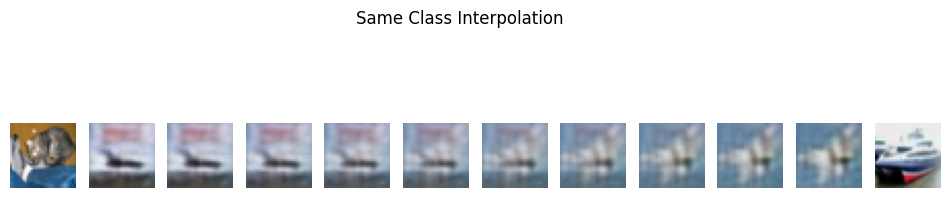

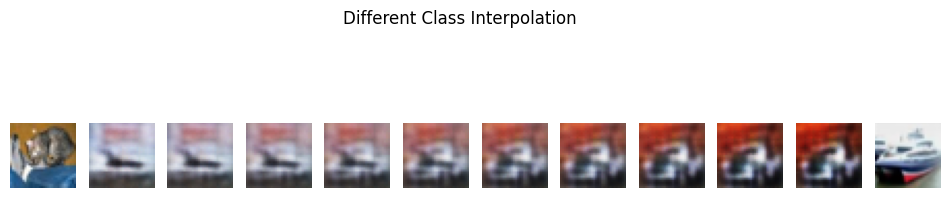

In [60]:
# ===================== YOUR CODE HERE ======================
same_interp = CAE_LATENT_SPACE_Trainer.interpolate_same_class(CIFAR_10_testloader, steps=10)
diff_interp = CAE_LATENT_SPACE_Trainer.interpolate_different_classes(CIFAR_10_testloader, steps=10)  #diff
if same_interp is not None:
    imgs, labs = next(iter(CIFAR_10_testloader))
    CAE_LATENT_SPACE_Trainer.visualize_interpolation(imgs[0:1], imgs[1:2], same_interp, "Same Class Interpolation")
if diff_interp is not None:
    imgs, labs = next(iter(CIFAR_10_testloader))
    CAE_LATENT_SPACE_Trainer.visualize_interpolation(imgs[0:1], imgs[1:2], diff_interp, "Different Class Interpolation")
# ===========================================================
##################### shit raise NotImplementedError

<hr>

### <h1 style="text-align: left;">Task 7 | <span style="color: #9370DB;">End</span></h1>

<hr>

<hr>

### <h1 style="text-align: left;"> Save Results | <span style="color: #9370DB;">Update JSON</span></h1>

<hr>

In [61]:
import json

print(json.dumps(Overall_Results, indent=4))

# overwrite same file with final results
with open(RESULTS_FILE, 'w') as f:
    json.dump(Overall_Results, f, indent=4)

print("Final JSON saved:", RESULTS_FILE)


{
    "Task 1": {
        "Train Loss (Last Epoch)": 0.01226507362216711,
        "Test Loss (Last Epoch)": 0.012185810287296771,
        "Train Loss (Minimum)": 0.01226507362216711,
        "Test Loss (Minimum)": 0.012185810287296771
    },
    "Task 2": {
        "Train Loss (Last Epoch)": 0.0054886116907000545,
        "Test Loss (Last Epoch)": 0.005338935081660747,
        "Train Loss (Minimum)": 0.0054886116907000545,
        "Test Loss (Minimum)": 0.005338935081660747
    },
    "Task 3": {
        "Train Loss (Last Epoch)": 0.02003809144993623,
        "Test Loss (Last Epoch)": 0.019556718319654463,
        "Train Loss (Minimum)": 0.02003809144993623,
        "Test Loss (Minimum)": 0.019556718319654463
    },
    "Task 4": {
        "Train Loss (Last Epoch)": 0.00966685673991839,
        "Test Loss (Last Epoch)": 0.009548647959530353,
        "Train Loss (Minimum)": 0.00966685673991839,
        "Test Loss (Minimum)": 0.009480258344113826
    },
    "Task 5": {
        "Train Los

<hr>

### <h1 style="text-align: center;">THE END</h1>

<hr>